In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

!pip install -q timm captum shap grad-cam scikit-image opencv-python-headless tabulate
!pip install -q diffusers transformers accelerate

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 123.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 43.7 MB/s eta 0:00:00


In [3]:
from pathlib import Path
import zipfile

# ----- Drive (input + persistent output) -----
DRIVE_ROOT      = Path('/content/drive/MyDrive/Thesis')
THESIS_ZIP      = DRIVE_ROOT / 'Thesis.zip'          # single outer zip
RESULTS_ROOT    = DRIVE_ROOT / 'results'
CHECKPOINTS_DIR = DRIVE_ROOT / 'checkpoints'

In [4]:
LOCAL_ROOT   = Path('/content/data')
APTOS_DIR    = LOCAL_ROOT / 'aptos'
EYEQ_DIR     = LOCAL_ROOT / 'eyeq'
PRISTINE_DIR = LOCAL_ROOT / 'pristine'
DEGRADED_DIR = LOCAL_ROOT / 'degraded'
ENHANCED_DIR = LOCAL_ROOT / 'enhanced'

PHASE_DIRS = {
    'phase1_data_engineering':   RESULTS_ROOT / 'phase1_data_engineering',
    'phase2_model_benchmarking': RESULTS_ROOT / 'phase2_model_benchmarking',
    'phase3_xai_benchmark':      RESULTS_ROOT / 'phase3_xai_benchmark',
    'phase4_genai_enhancement':  RESULTS_ROOT / 'phase4_genai_enhancement',
    'phase5_quality_ensemble':   RESULTS_ROOT / 'phase5_quality_ensemble',
}
PHASE_SUBDIRS = ('metrics', 'plots', 'samples', 'logs')

In [5]:
for p in [LOCAL_ROOT, PRISTINE_DIR, DEGRADED_DIR, ENHANCED_DIR,
          RESULTS_ROOT, CHECKPOINTS_DIR]:
    p.mkdir(parents=True, exist_ok=True)
for phase_dir in PHASE_DIRS.values():
    for sub in PHASE_SUBDIRS:
        (phase_dir / sub).mkdir(parents=True, exist_ok=True)

print('Drive zip   :', THESIS_ZIP, '(exists:', THESIS_ZIP.exists(), ')')
print('Drive results tree:')
for k, v in PHASE_DIRS.items():
    print(f'  {k:35s} -> {v}')

Drive zip   : /content/drive/MyDrive/Thesis/Thesis.zip (exists: True )
Drive results tree:
  phase1_data_engineering             -> /content/drive/MyDrive/Thesis/results/phase1_data_engineering
  phase2_model_benchmarking           -> /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking
  phase3_xai_benchmark                -> /content/drive/MyDrive/Thesis/results/phase3_xai_benchmark
  phase4_genai_enhancement            -> /content/drive/MyDrive/Thesis/results/phase4_genai_enhancement
  phase5_quality_ensemble             -> /content/drive/MyDrive/Thesis/results/phase5_quality_ensemble


In [ ]:
import zipfile, shutil

def extract_recursive(src_zip: Path, dest_dir: Path):
    """Extract outer zip, then recursively extract any inner *.zip files."""
    if not src_zip.exists():
        raise FileNotFoundError(f'Missing zip: {src_zip}')
    print(f'[extract] {src_zip.name} -> {dest_dir}')
    with zipfile.ZipFile(src_zip) as zf:
        zf.extractall(dest_dir)
    # Find and extract any inner .zip files (e.g. APTOS.zip, EYEQ.zip inside Thesis.zip)
    while True:
        inner = [p for p in dest_dir.rglob('*.zip')]
        if not inner:
            break
        for iz in inner:
            target = iz.parent / iz.stem        # e.g. .../APTOS/
            target.mkdir(exist_ok=True)
            print(f'  inner zip: {iz.name} -> {target}')
            with zipfile.ZipFile(iz) as zf:
                zf.extractall(target)
            iz.unlink()                          # delete the .zip after extracting

extract_recursive(THESIS_ZIP, LOCAL_ROOT)

# Auto-detect APTOS and EyeQ folders (case-insensitive) and symlink to canonical names
def _find_dir(root: Path, keywords):
    for p in root.rglob('*'):
        if p.is_dir() and any(k in p.name.lower() for k in keywords):
            return p
    return None

aptos_src = _find_dir(LOCAL_ROOT, ['aptos'])
eyeq_src  = _find_dir(LOCAL_ROOT, ['eyeq', 'eye_q', 'eye-q'])
print('Detected APTOS dir:', aptos_src)
print('Detected EyeQ  dir:', eyeq_src)

# Make canonical paths point at whatever was extracted
for canonical, real in [(APTOS_DIR, aptos_src), (EYEQ_DIR, eyeq_src)]:
    if real is None:
        print(f'[warn] {canonical.name} not found — check Thesis.zip contents')
        continue
    if canonical.exists() and canonical.resolve() != real.resolve():
        shutil.rmtree(canonical) if canonical.is_dir() and not canonical.is_symlink() else canonical.unlink()
    if not canonical.exists():
        canonical.symlink_to(real, target_is_directory=True)
    print(f'  {canonical} -> {real}')

[extract] Thesis.zip -> /content/data


In [ ]:
def show_tree(root: Path, max_depth: int = 3):
    root = Path(root)
    for p in sorted(root.rglob('*')):
        depth = len(p.relative_to(root).parts)
        if depth > max_depth: continue
        kind = '/' if p.is_dir() else ''
        print(f'{"  "*(depth-1)}{p.name}{kind}')

print('=== APTOS ==='); show_tree(APTOS_DIR, max_depth=2)
print('\n=== EYEQ  ==='); show_tree(EYEQ_DIR,  max_depth=2)

In [ ]:
import torch
PHASE_DIRS = {
    'phase1_data_engineering':   RESULTS_ROOT / 'phase1_data_engineering',
    'phase2_model_benchmarking': RESULTS_ROOT / 'phase2_model_benchmarking',
    'phase3_xai_benchmark':      RESULTS_ROOT / 'phase3_xai_benchmark',
    'phase4_genai_enhancement':  RESULTS_ROOT / 'phase4_genai_enhancement',
    'phase5_quality_ensemble':   RESULTS_ROOT / 'phase5_quality_ensemble',
}
for p in [DEGRADED_DIR, ENHANCED_DIR, RESULTS_ROOT, CHECKPOINTS_DIR]:
    p.mkdir(parents=True, exist_ok=True)
for d in PHASE_DIRS.values():
    for sub in ('metrics', 'plots', 'samples', 'logs'):
        (d / sub).mkdir(parents=True, exist_ok=True)

# Auto-detect APTOS train CSV + image dir (case-insensitive)
APTOS_CSV    = next(p for p in APTOS_DIR.rglob('*.csv') if 'train' in p.name.lower())
APTOS_IMAGES = next(p for p in APTOS_DIR.rglob('*train_images*') if p.is_dir())
EYEQ_CSV     = next(EYEQ_DIR.rglob('*.csv'), None)

# Common constants
NUM_CLASSES = 5
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
IMAGE_SIZE  = 224
SEED        = 42
VAL_SPLIT, TEST_SPLIT = 0.15, 0.15

MODEL_NAMES = ('resnet50', 'efficientnet_b3', 'vit_base')
TIMM_NAMES  = {'resnet50': 'resnet50',
               'efficientnet_b3': 'efficientnet_b3',
               'vit_base': 'vit_base_patch16_224'}
TRAIN_CFG = dict(batch_size=32, num_workers=2, epochs=15,
                 lr=3e-4, weight_decay=1e-4, label_smoothing=0.05,
                 mixed_precision=True)

DEGRADATION_TYPES  = ('blur', 'exposure', 'noise')
DEGRADATION_LEVELS = ('low', 'mid', 'high')
DEGRADATION_PARAMS = {
    'blur':     {'low': 2.0,  'mid': 5.0,  'high': 9.0},
    'exposure': {'low': 0.7,  'mid': 0.4,  'high': 0.2},
    'noise':    {'low': 0.02, 'mid': 0.06, 'high': 0.12},
}
EYEQ_QUALITY_LABELS = {0: 'good', 1: 'usable', 2: 'reject'}

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('APTOS csv   :', APTOS_CSV)
print('APTOS images:', APTOS_IMAGES)
print('EyeQ csv    :', EYEQ_CSV)
print('Device      :', DEVICE)

In [ ]:
import json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from tqdm.auto import tqdm

import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torch.cuda.amp import GradScaler, autocast
from torchvision import transforms as T
import timm
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from scipy.stats import spearmanr
from skimage.segmentation import slic

TFM_TRAIN = T.Compose([T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
                        T.RandomHorizontalFlip(),
                        T.RandomRotation(15),
                        T.ColorJitter(0.1, 0.1, 0.1),
                        T.ToTensor(),
                        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
TFM_EVAL  = T.Compose([T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
                        T.ToTensor(),
                        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def load_tensor(path: Path) -> torch.Tensor:
    return TFM_EVAL(Image.open(path).convert('RGB')).unsqueeze(0).to(DEVICE)

In [ ]:
class APTOSDataset(Dataset):
    """Resolves images via IMAGE_INDEX so any extension / nested layout works."""
    def __init__(self, csv_path, images_dir, transform):
        self.df = pd.read_csv(csv_path)
        self.images_dir = Path(images_dir)   # kept for API compatibility, not used
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(resolve_image(row['id_code'])).convert('RGB')
        return self.transform(img), int(row['diagnosis']), row['id_code']

class FolderDataset(Dataset):
    """Reads `<root>/manifest.csv` (cols: id_code, diagnosis, rel_path)."""
    def __init__(self, root, transform=TFM_EVAL):
        self.root = Path(root); self.df = pd.read_csv(self.root / 'manifest.csv')
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(self.root / row['rel_path']).convert('RGB')
        return self.transform(img), int(row['diagnosis']), row['id_code']

In [ ]:
# === Improved training infrastructure ===
import math
from contextlib import contextmanager
from collections import Counter
from torch.utils.data import WeightedRandomSampler, Subset
from sklearn.model_selection import train_test_split

# 1) STRATIFIED SPLIT — keeps class proportions consistent across train/val/test
def stratified_split_indices(labels, val_frac=0.15, test_frac=0.15, seed=SEED):
    idx = np.arange(len(labels)); labels = np.array(labels)
    tr_idx, te_idx = train_test_split(idx, test_size=test_frac, stratify=labels, random_state=seed)
    rel_val = val_frac / (1 - test_frac)
    tr_idx, va_idx = train_test_split(tr_idx, test_size=rel_val,
                                       stratify=labels[tr_idx], random_state=seed)
    return tr_idx.tolist(), va_idx.tolist(), te_idx.tolist()

# 2) CLASS WEIGHTS + BALANCED SAMPLER
def class_weights_tensor(labels, num_classes=NUM_CLASSES):
    cnt = Counter(labels); n = sum(cnt.values())
    return torch.tensor([n / (num_classes * max(cnt.get(i, 0), 1)) for i in range(num_classes)],
                         dtype=torch.float)

def balanced_sampler(labels):
    cnt = Counter(labels)
    w = [1.0 / cnt[l] for l in labels]
    return WeightedRandomSampler(w, num_samples=len(w), replacement=True)

# 3) FOCAL LOSS (handles soft targets from MixUp + per-class weights)
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=None, label_smoothing=0.0):
        super().__init__(); self.gamma, self.alpha, self.ls = gamma, alpha, label_smoothing
    def forward(self, logits, targets):
        if targets.dim() > 1:                       # soft labels (MixUp)
            log_p = F.log_softmax(logits, dim=-1)
            return -(targets * log_p).sum(-1).mean()
        ce = F.cross_entropy(logits, targets, weight=self.alpha,
                              reduction='none', label_smoothing=self.ls)
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()

# 4) EMA — exponential moving average of weights, +0.5–1% reliably
class EMA:
    def __init__(self, model, decay=0.999):
        self.decay = decay
        self.shadow = {n: p.detach().clone() for n, p in model.named_parameters() if p.requires_grad}
    def update(self, model):
        with torch.no_grad():
            for n, p in model.named_parameters():
                if p.requires_grad:
                    self.shadow[n].mul_(self.decay).add_(p.detach(), alpha=1 - self.decay)
    @contextmanager
    def applied(self, model):
        backup = {n: p.detach().clone() for n, p in model.named_parameters() if p.requires_grad}
        for n, p in model.named_parameters():
            if p.requires_grad: p.data.copy_(self.shadow[n])
        try: yield
        finally:
            for n, p in model.named_parameters():
                if p.requires_grad: p.data.copy_(backup[n])

# 5) STRONG TRAIN AUGMENTATION (medical-imaging safe — no extreme hue shifts)
TFM_TRAIN_STRONG = T.Compose([
    T.Resize((IMAGE_SIZE + 32, IMAGE_SIZE + 32)),
    T.RandomCrop(IMAGE_SIZE),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(25),
    T.RandAugment(num_ops=2, magnitude=7),
    T.ColorJitter(0.15, 0.15, 0.15, 0.03),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    T.RandomErasing(p=0.25),
])

# 6) MIXUP / CUTMIX (timm's implementation)
from timm.data import Mixup

# 7) LAYER-WISE LR DECAY (LRD) — critical for ViT fine-tuning
def vit_lrd_param_groups(model, base_lr, decay=0.75, weight_decay=5e-2):
    n_layers = len(model.blocks) + 1
    groups = []
    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        if n.startswith('head'):                                  depth = n_layers
        elif n.startswith('blocks'):                              depth = int(n.split('.')[1])
        elif any(n.startswith(s) for s in
                 ('patch_embed', 'cls_token', 'pos_embed', 'norm')): depth = 0
        else:                                                     depth = 0
        lr_scale = decay ** (n_layers - depth)
        groups.append({'params': p, 'lr': base_lr * lr_scale,
                       'weight_decay': 0.0 if p.ndim <= 1 else weight_decay})
    return groups

# 8) WARMUP + COSINE LR SCHEDULE
def warmup_cosine(optimizer, warmup_epochs, total_epochs, steps_per_epoch):
    def lr_lambda(step):
        epoch = step / max(steps_per_epoch, 1)
        if epoch < warmup_epochs:
            return epoch / max(warmup_epochs, 1)
        prog = (epoch - warmup_epochs) / max(total_epochs - warmup_epochs, 1)
        return 0.5 * (1 + math.cos(math.pi * min(prog, 1.0)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

# 9) PER-ARCHITECTURE HYPERPARAMETERS
HPARAMS = {
    'resnet50':        dict(lr=3e-4, wd=1e-4, epochs=25, mixup=0.2, ls=0.1, gamma=1.5, warmup=3, llrd=None),
    'efficientnet_b3': dict(lr=2e-4, wd=1e-5, epochs=25, mixup=0.2, ls=0.1, gamma=2.0, warmup=3, llrd=None),
    'vit_base':        dict(lr=5e-5, wd=5e-2, epochs=30, mixup=0.4, ls=0.1, gamma=2.0, warmup=5, llrd=0.75),
}

print('Improved training infrastructure loaded.')

In [ ]:
def find_in_folder(folder, id_code, exts=('.jpg', '.png', '.jpeg')):
    """Return the actual file path for id_code in folder, regardless of extension."""
    for ext in exts:
        p = Path(folder) / f'{id_code}{ext}'
        if p.exists():
            return p
    raise FileNotFoundError(f'{id_code} not found in {folder} (tried {exts})')

In [ ]:
def build_model(name, pretrained=True):
    m = timm.create_model(TIMM_NAMES[name], pretrained=pretrained, num_classes=NUM_CLASSES)
    m._dr_arch = name
    return m

def load_classifier(name):
    m = build_model(name, pretrained=False).to(DEVICE)
    state = torch.load(CHECKPOINTS_DIR / f'{name}_best.pt', map_location=DEVICE, weights_only=False)
    m.load_state_dict(state['state_dict']); m.eval()
    return m

def get_xai_target_layer(model):
    a = model._dr_arch
    if a == 'resnet50':        return model.layer4[-1]
    if a == 'efficientnet_b3': return model.blocks[-1]
    if a == 'vit_base':        return model.blocks[-1].norm1
    raise ValueError(a)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); ys, ps, probs = [], [], []
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        prob = torch.softmax(model(x), 1).cpu().numpy()
        probs.append(prob); ps.append(prob.argmax(1)); ys.append(y.numpy())
    y = np.concatenate(ys); p = np.concatenate(ps); pr = np.concatenate(probs)
    out = {'accuracy': accuracy_score(y, p), 'f1_macro': f1_score(y, p, average='macro')}
    try: out['auc_macro_ovr'] = roc_auc_score(y, pr, average='macro', multi_class='ovr')
    except ValueError: out['auc_macro_ovr'] = float('nan')
    return out

def train_one(model, train_loader, val_loader, ckpt_path, history_csv,
              epochs=TRAIN_CFG['epochs'], lr=TRAIN_CFG['lr'],
              wd=TRAIN_CFG['weight_decay'], ls=TRAIN_CFG['label_smoothing'],
              amp=TRAIN_CFG['mixed_precision']):
    model = model.to(DEVICE)
    optim  = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched  = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=epochs)
    crit   = nn.CrossEntropyLoss(label_smoothing=ls)
    scaler = GradScaler(enabled=amp)
    best_f1, history = -1.0, []
    for ep in range(epochs):
        model.train(); running, seen = 0.0, 0
        pbar = tqdm(train_loader, desc=f'epoch {ep+1}/{epochs}', leave=False)
        for x, y, _ in pbar:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            optim.zero_grad(set_to_none=True)
            with autocast(enabled=amp):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(optim); scaler.update()
            running += loss.item() * x.size(0); seen += x.size(0)
            pbar.set_postfix(loss=running/seen)
        sched.step()
        m = evaluate(model, val_loader)
        history.append({'epoch': ep+1, 'train_loss': running/seen, **m})
        print(f'  val: acc={m["accuracy"]:.4f}  f1={m["f1_macro"]:.4f}  auc={m["auc_macro_ovr"]:.4f}')
        if m['f1_macro'] > best_f1:
            best_f1 = m['f1_macro']
            torch.save({'state_dict': model.state_dict(), 'arch': model._dr_arch, 'val': m}, ckpt_path)
    pd.DataFrame(history).to_csv(history_csv, index=False)
    return pd.DataFrame(history)

In [ ]:
def gradcam_heatmap(model, x, target_class=None):
    layer = get_xai_target_layer(model)
    acts, grads = {}, {}
    h1 = layer.register_forward_hook(lambda _, __, o: acts.update(v=o.detach()))
    h2 = layer.register_full_backward_hook(lambda _, gi, go: grads.update(v=go[0].detach()))
    try:
        model.zero_grad(set_to_none=True)
        x = x.clone().requires_grad_(True)
        logits = model(x)
        if target_class is None:
            target_class = int(logits.argmax(1).item())
        logits[0, target_class].backward()
        a, g = acts['v'][0], grads['v'][0]
        cam = torch.relu((g.mean(dim=(1, 2))[:, None, None] * a).sum(0))
        cam -= cam.min()
        if cam.max() > 0: cam /= cam.max()
        cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode='bilinear', align_corners=False)
        return cam.squeeze().detach().cpu().numpy()
    finally:
        h1.remove(); h2.remove()

@torch.no_grad()
def attention_rollout(model, x, target_class=None):
    attns, handles = [], []
    for blk in model.blocks:
        attn_module = blk.attn
        def make_hook(store, mod):
            def _h(module, inp, out):
                B, N, C = inp[0].shape
                qkv = mod.qkv(inp[0]).reshape(B, N, 3, mod.num_heads, C // mod.num_heads).permute(2, 0, 3, 1, 4)
                q, k, _ = qkv[0], qkv[1], qkv[2]
                a = (q @ k.transpose(-2, -1)) * mod.scale
                store.append(a.softmax(-1).detach())
            return _h
        handles.append(attn_module.register_forward_hook(make_hook(attns, attn_module)))
    try: _ = model(x)
    finally:
        for h in handles: h.remove()
    res = None
    for a in attns:
        a = a.mean(1) + torch.eye(a.size(-1), device=a.device)
        a = a / a.sum(-1, keepdim=True)
        res = a if res is None else a @ res
    cls = res[0, 0, 1:]; side = int(cls.numel() ** 0.5)
    h = F.interpolate(cls.reshape(side, side)[None, None],
                       size=x.shape[-2:], mode='bilinear', align_corners=False).squeeze().cpu().numpy()
    if h.max() > h.min(): h = (h - h.min()) / (h.max() - h.min())
    return h

def shap_heatmap(model, x, target_class=None, n_samples=60, n_segments=40):
    import shap
    img = x.squeeze(0).permute(1, 2, 0).cpu().numpy()
    seg = slic(img, n_segments=n_segments, compactness=10, start_label=0)
    def f(masks):
        out = np.zeros((masks.shape[0], NUM_CLASSES), dtype=np.float32)
        for i, m in enumerate(masks):
            keep = np.isin(seg, np.where(m == 1)[0])
            masked = img.copy(); masked[~keep] = img.mean(axis=(0, 1))
            t = torch.tensor(masked).permute(2, 0, 1).unsqueeze(0).float().to(DEVICE)
            with torch.no_grad():
                out[i] = torch.softmax(model(t), 1).cpu().numpy()[0]
        return out
    n_super = int(seg.max() + 1)
    explainer = shap.KernelExplainer(f, np.zeros((1, n_super)))
    sv = explainer.shap_values(np.ones((1, n_super)), nsamples=n_samples)
    if target_class is None:
        with torch.no_grad():
            target_class = int(model(x).argmax(1).item())
    sv = sv[target_class][0]
    heat = np.zeros(seg.shape, dtype=np.float32)
    for sid, val in enumerate(sv):
        heat[seg == sid] = val
    if heat.max() > heat.min():
        heat = (heat - heat.min()) / (heat.max() - heat.min())
    return heat

In [ ]:
@torch.no_grad()
def _prob_for(model, x, cls): return torch.softmax(model(x), 1)[0, cls].item()

def deletion_auc(model, x, heatmap, target_class, steps=30):
    H, W = heatmap.shape
    order = np.argsort(-heatmap.flatten())
    chunk = max(1, len(order) // steps)
    mean_pix = x.mean(dim=(2, 3), keepdim=True)
    probs = []
    for s in range(steps + 1):
        idx = order[: s * chunk]
        rows, cols = np.unravel_index(idx, (H, W))
        x_mod = x.clone()
        x_mod[0, :, rows, cols] = mean_pix.expand_as(x)[0, :, rows, cols]
        probs.append(_prob_for(model, x_mod, target_class))
    return float(np.trapezoid(probs, dx=1/steps))

def insertion_auc(model, x, heatmap, target_class, steps=30):
    H, W = heatmap.shape
    order = np.argsort(-heatmap.flatten())
    chunk = max(1, len(order) // steps)
    base = F.avg_pool2d(x, 15, stride=1, padding=7)
    probs = []
    for s in range(steps + 1):
        idx = order[: s * chunk]
        rows, cols = np.unravel_index(idx, (H, W))
        x_mod = base.clone(); x_mod[0, :, rows, cols] = x[0, :, rows, cols]
        probs.append(_prob_for(model, x_mod, target_class))
    return float(np.trapezoid(probs, dx=1/steps))

def stability_spearman(h1, h2):
    rho, _ = spearmanr(h1.flatten(), h2.flatten())
    return float(rho) if rho == rho else 0.0

def localization_iou(heatmap, mask, percentile=80):
    if mask is None: return float('nan')
    thr  = np.percentile(heatmap, percentile)
    pred = heatmap >= thr
    inter = np.logical_and(pred, mask).sum()
    union = np.logical_or(pred, mask).sum()
    return float(inter/union) if union > 0 else float('nan')

**DATA ENGINEERING**

In [ ]:
P1 = PHASE_DIRS['phase1_data_engineering']

# 1.1 Quality filter (EyeQ -> pristine subset; falls back to full APTOS)
def filter_pristine(aptos_csv, eyeq_csv, out_csv,
                    keep_quality=('good',),
                    eyeq_id_col='image', eyeq_quality_col='quality',
                    aptos_id_col='id_code'):
    aptos = pd.read_csv(aptos_csv)
    if eyeq_csv is None or not Path(eyeq_csv).exists():
        print('[fallback] No EyeQ CSV — keeping all APTOS rows.')
        aptos.to_csv(out_csv, index=False); return aptos
    eyeq = pd.read_csv(eyeq_csv)
    if pd.api.types.is_integer_dtype(eyeq[eyeq_quality_col]):
        eyeq['__q'] = eyeq[eyeq_quality_col].map(EYEQ_QUALITY_LABELS)
    else:
        eyeq['__q'] = eyeq[eyeq_quality_col].astype(str).str.lower()
    keep_ids = set(eyeq.loc[eyeq['__q'].isin(keep_quality), eyeq_id_col].astype(str))
    pristine = aptos[aptos[aptos_id_col].astype(str).isin(keep_ids)].reset_index(drop=True)
    if len(pristine) == 0:
        print('[warn] EyeQ filter removed all rows — falling back to full APTOS.')
        aptos.to_csv(out_csv, index=False); return aptos
    pristine.to_csv(out_csv, index=False); return pristine

PRISTINE_CSV = P1 / 'metrics' / 'pristine_split.csv'
pristine_df = filter_pristine(APTOS_CSV, EYEQ_CSV, PRISTINE_CSV)
print(f'kept {len(pristine_df)} / {pd.read_csv(APTOS_CSV).shape[0]} images')
pristine_df.head()

[warn] EyeQ filter removed all rows — falling back to full APTOS.
kept 2930 / 2930 images


,id_code,diagnosis
0,1ae8c165fd53,2
1,1b329a127307,1
2,1b32e1d775ea,4
3,1b3647865779,0
4,1b398c0494d1,0


In [ ]:
# Diagnose the actual APTOS image layout
print('APTOS_IMAGES :', APTOS_IMAGES)
print('Exists?       :', APTOS_IMAGES.exists())
all_files = list(APTOS_IMAGES.rglob('*'))
img_files = [p for p in all_files if p.is_file() and p.suffix.lower() in ('.png', '.jpg', '.jpeg')]
print(f'Total files under APTOS_IMAGES (any depth): {len(all_files)}')
print(f'Image files found                          : {len(img_files)}')
if img_files:
    print('Sample image paths:')
    for p in img_files[:5]:
        print(' ', p.relative_to(APTOS_IMAGES))
print('\nSample id_code from CSV:', pristine_df["id_code"].iloc[0])
print('Sample image stem      :', img_files[0].stem if img_files else '(none)')

APTOS_IMAGES : /content/data/aptos/train_images
Exists?       : True
Total files under APTOS_IMAGES (any depth): 2934
Image files found                          : 2930
Sample image paths:
  train_images/4350a1b2f3cb.jpg
  train_images/4ef0b485a7da.jpg
  train_images/7f2123bc89a3.jpg
  train_images/ba4e62c11cc0.jpg
  train_images/3c78bfca247b.jpg

Sample id_code from CSV: 1ae8c165fd53
Sample image stem      : 4350a1b2f3cb


In [ ]:
# Build a stem -> path index so we don't care about extension or subfolder depth.
# Searches all of APTOS_DIR (not just APTOS_IMAGES) in case auto-detection picked the wrong folder.
print('Indexing APTOS images...')
IMAGE_INDEX = {}
for p in APTOS_DIR.rglob('*'):
    if p.is_file() and p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.tif', '.tiff'):
        IMAGE_INDEX[p.stem] = p
print(f'Indexed {len(IMAGE_INDEX)} images.')

# Sanity check against the CSV
csv_ids = pristine_df['id_code'].astype(str).tolist()
matched = [i for i in csv_ids if i in IMAGE_INDEX]
missing = [i for i in csv_ids if i not in IMAGE_INDEX]
print(f'CSV ids matched: {len(matched)}/{len(csv_ids)}')
if missing:
    print(f'Example missing id: {missing[0]}')
    print('Example indexed stems:', list(IMAGE_INDEX)[:3])
    raise SystemExit('CSV ids do not match image filenames — inspect the diagnostic output above.')

def resolve_image(id_code):
    """Get the actual image path for an APTOS id_code, regardless of extension or folder."""
    p = IMAGE_INDEX.get(str(id_code))
    if p is None:
        raise FileNotFoundError(f'No image indexed for id_code={id_code!r}')
    return p

Indexing APTOS images...
Indexed 3662 images.
CSV ids matched: 2930/2930


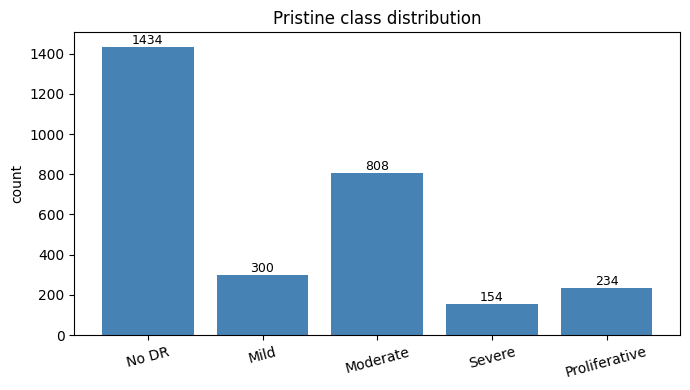

Saved: /content/drive/MyDrive/Thesis/results/phase1_data_engineering/plots/class_distribution.png


In [ ]:
# 1.2 Class-balance plot
counts = pristine_df['diagnosis'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([CLASS_NAMES[i] for i in counts.index], counts.values, color='steelblue')
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v, str(v), ha='center', va='bottom', fontsize=9)
ax.set_title('Pristine class distribution'); ax.set_ylabel('count')
plt.xticks(rotation=15); plt.tight_layout()
out = P1 / 'plots' / 'class_distribution.png'
plt.savefig(out, dpi=150); plt.show()
print('Saved:', out)

In [ ]:
# 1.3 Synthetic degradation primitives
def _np(img):  return np.array(img.convert('RGB'))
def _pil(arr): return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))

def gaussian_blur(img, sigma):
    k = max(3, int(2 * round(3 * sigma) + 1))
    return _pil(cv2.GaussianBlur(_np(img), (k, k), sigmaX=sigma, sigmaY=sigma))

def exposure_shift(img, gain): return _pil(_np(img).astype(np.float32) * gain)
def gaussian_noise(img, std_frac):
    arr = _np(img).astype(np.float32)
    return _pil(arr + np.random.normal(0, std_frac * 255, arr.shape))

DEGRADERS = {'blur': gaussian_blur, 'exposure': exposure_shift, 'noise': gaussian_noise}
def apply_degradation(img, kind, level):
    return DEGRADERS[kind](img, DEGRADATION_PARAMS[kind][level])

In [ ]:
!du -sh /content/data/* 2>/dev/null
!df -h /content

0	/content/data/aptos
323M	/content/data/degraded
4.0K	/content/data/enhanced
0	/content/data/eyeq
4.0K	/content/data/pristine
90G	/content/data/Thesis
Filesystem      Size  Used Avail Use% Mounted on
overlay         236G  135G  102G  57% /


In [ ]:
import shutil

# Use rm -rf for a more forceful deletion to handle potential disk full issues
# or lingering file handles.
!rm -rf {DEGRADED_DIR}

# Ensure the base directory exists before recreating subdirectories.
DEGRADED_DIR.mkdir(parents=True, exist_ok=True)

# Check disk space after deletion to confirm space is freed.
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         236G  134G  102G  57% /


In [ ]:
# 1.4 (parallel + resized + JPEG) — ~50-100x smaller on disk
from concurrent.futures import ThreadPoolExecutor, as_completed
import os

MAX_WORKERS = max(4, (os.cpu_count() or 2) * 2)
print(f'Using {MAX_WORKERS} worker threads')

DEG_SAVE_SIZE    = (IMAGE_SIZE, IMAGE_SIZE)   # 224x224 — same as model input
DEG_SAVE_FORMAT  = 'JPEG'                      # huge size win vs PNG
DEG_SAVE_QUALITY = 90                          # visually indistinguishable for retinal images
DEG_SAVE_EXT     = '.jpg'

def _process_one(row, kind, level, out_dir):
    try:
        src = resolve_image(row['id_code'])
    except FileNotFoundError:
        return None
    img = Image.open(src).convert('RGB').resize(DEG_SAVE_SIZE, Image.BILINEAR)
    out_img = apply_degradation(img, kind, level)
    rel = f"{row['id_code']}{DEG_SAVE_EXT}"
    out_img.save(out_dir / rel, format=DEG_SAVE_FORMAT, quality=DEG_SAVE_QUALITY, optimize=False)
    return {'id_code': row['id_code'], 'diagnosis': int(row['diagnosis']),
            'degradation': kind, 'level': level, 'rel_path': rel}

def build_split_parallel(kind, level):
    out_dir = DEGRADED_DIR / kind / level
    out_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as ex:
        futures = [ex.submit(_process_one, r, kind, level, out_dir)
                   for _, r in pristine_df.iterrows()]
        for fut in tqdm(as_completed(futures), total=len(futures),
                         desc=f'{kind}-{level}', leave=False):
            r = fut.result()
            if r is not None:
                rows.append(r)
    df = pd.DataFrame(rows)
    df.to_csv(out_dir / 'manifest.csv', index=False)
    df.to_csv(P1 / 'metrics' / f'manifest_{kind}_{level}.csv', index=False)
    return df

for k in DEGRADATION_TYPES:
    for l in DEGRADATION_LEVELS:
        m = build_split_parallel(k, l)
        print(f'  {k}/{l}: {len(m)} images')

!df -h /content"

Using 24 worker threads


blur-low:   0%|          | 0/2930 [00:00<?, ?it/s]

  blur/low: 2930 images


blur-mid:   0%|          | 0/2930 [00:00<?, ?it/s]

  blur/mid: 2930 images


blur-high:   0%|          | 0/2930 [00:00<?, ?it/s]

... (9 outputs left out)

noise-mid:   0%|          | 0/2930 [00:00<?, ?it/s]

  noise/mid: 2930 images


noise-high:   0%|          | 0/2930 [00:00<?, ?it/s]

  noise/high: 2930 images
/bin/bash: -c: line 1: unexpected EOF while looking for matching `"'
/bin/bash: -c: line 2: syntax error: unexpected end of file


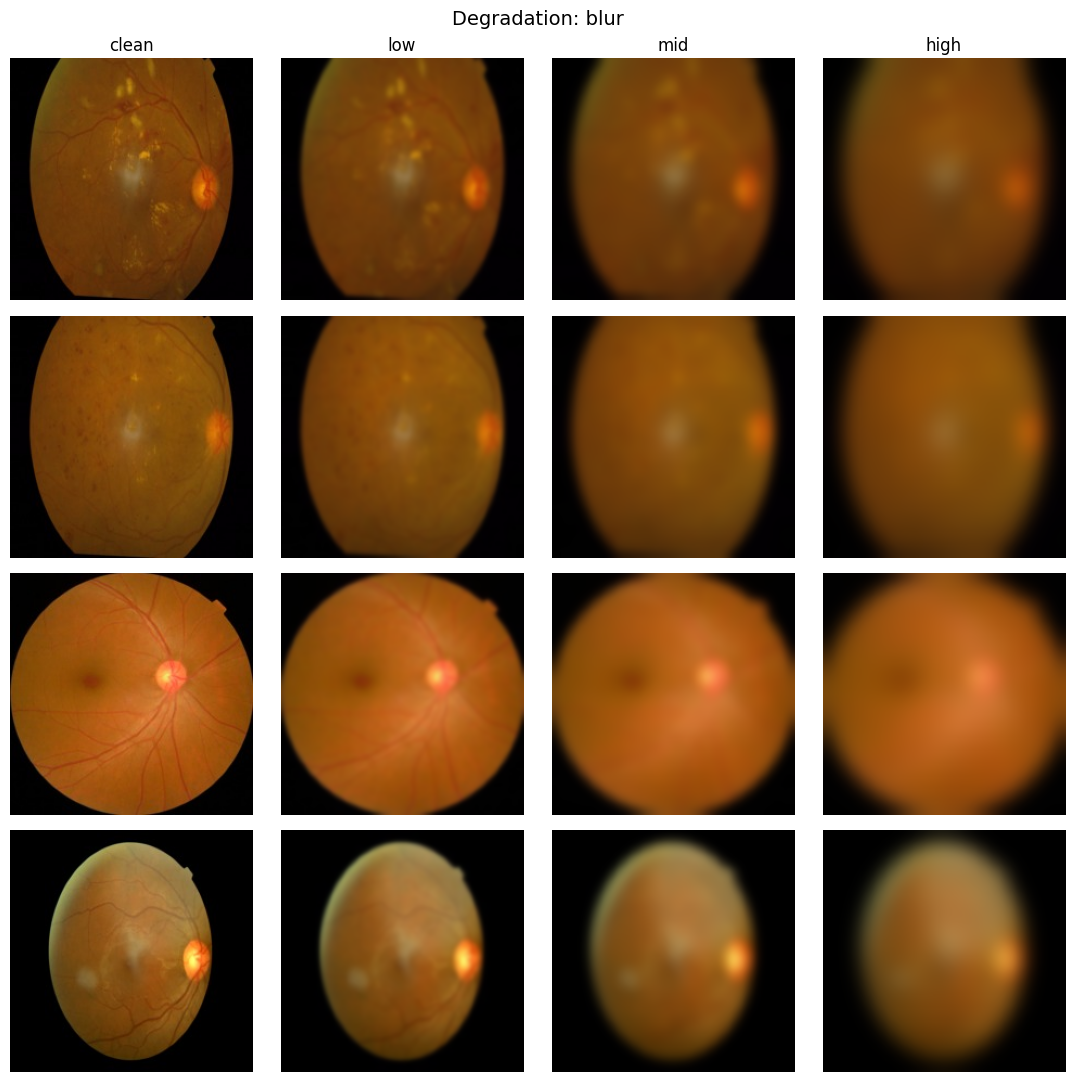

Saved: /content/drive/MyDrive/Thesis/results/phase1_data_engineering/samples/grid_blur.png


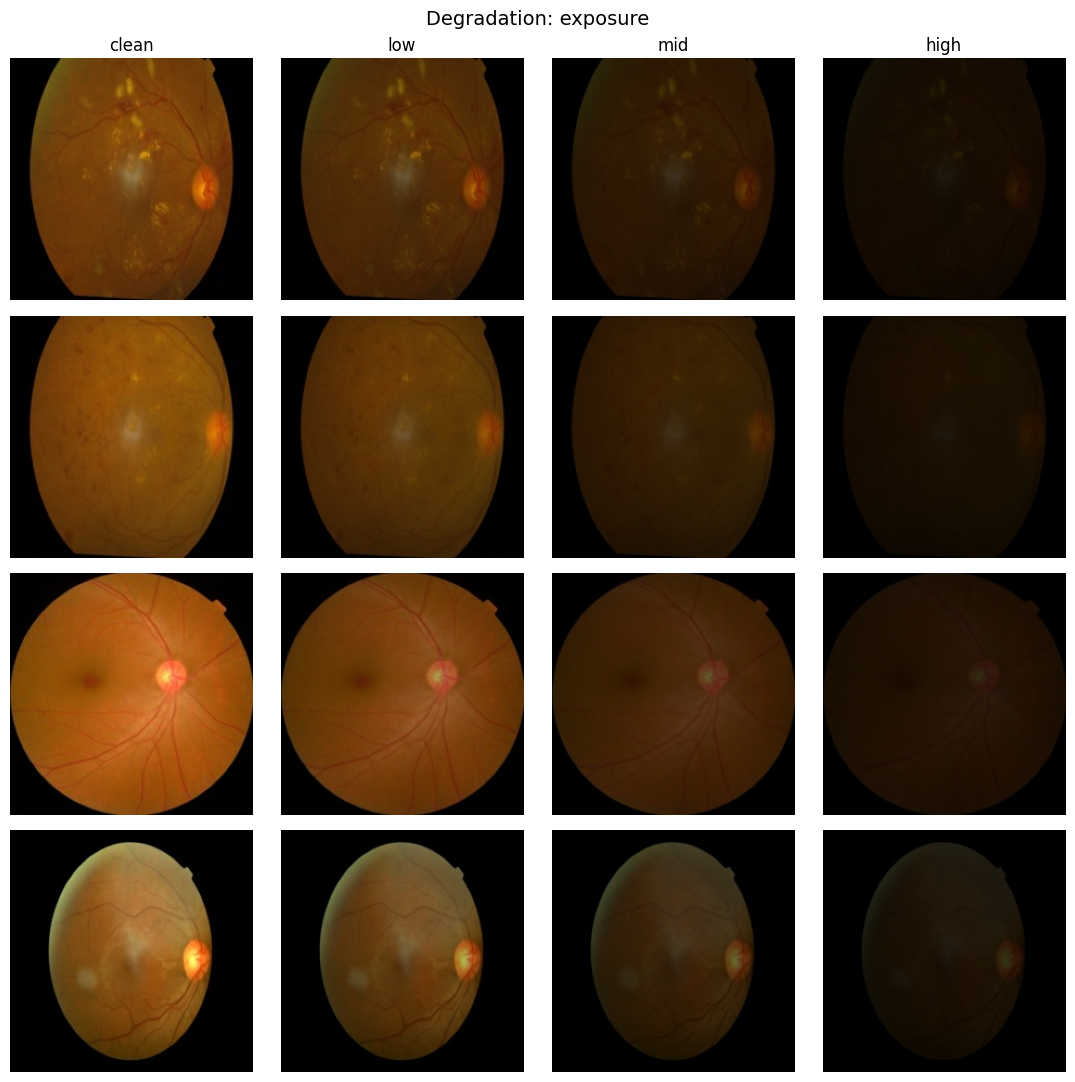

Saved: /content/drive/MyDrive/Thesis/results/phase1_data_engineering/samples/grid_exposure.png


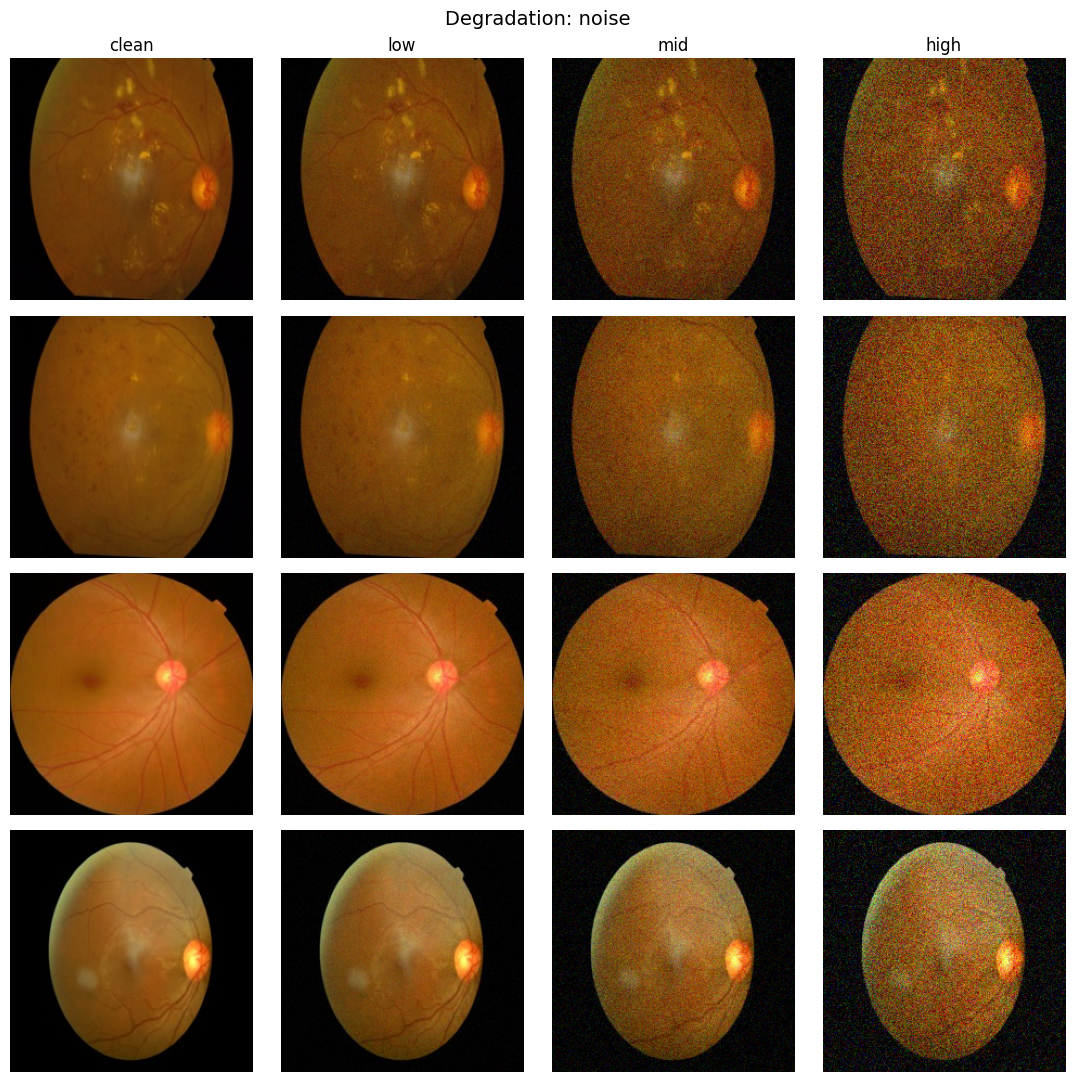

Saved: /content/drive/MyDrive/Thesis/results/phase1_data_engineering/samples/grid_noise.png


,degradation,level,n_images
0,blur,low,0
1,blur,mid,0
2,blur,high,0
3,exposure,low,0
4,exposure,mid,0
5,exposure,high,0
6,noise,low,0
7,noise,mid,0
8,noise,high,0


In [ ]:
# 1.5 Sample grids — extension-agnostic
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(pristine_df['id_code'].values, size=4, replace=False)
for kind in DEGRADATION_TYPES:
    fig, axes = plt.subplots(4, 4, figsize=(11, 11))
    for r, sid in enumerate(sample_ids):
        clean = Image.open(resolve_image(sid)).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
        axes[r, 0].imshow(clean); axes[r, 0].set_title('clean' if r == 0 else '')
        for c, lvl in enumerate(DEGRADATION_LEVELS, start=1):
            axes[r, c].imshow(apply_degradation(clean, kind, lvl))
            if r == 0: axes[r, c].set_title(lvl)
        for ax in axes[r]: ax.axis('off')
    fig.suptitle(f'Degradation: {kind}', fontsize=14); plt.tight_layout()
    out = P1 / 'samples' / f'grid_{kind}.png'
    plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
    print('Saved:', out)

# 1.6 Phase summary
summary = pd.DataFrame([{'degradation': k, 'level': l,
                          'n_images': len(list((DEGRADED_DIR/k/l).glob('*.png')))}
                         for k in DEGRADATION_TYPES for l in DEGRADATION_LEVELS])
summary.to_csv(P1 / 'metrics' / 'phase1_summary.csv', index=False)
summary

In [ ]:
# 2.1 (improved) — stratified split, per-class weights, balanced sampler
P2 = PHASE_DIRS['phase2_model_benchmarking']
PRISTINE_CSV = PHASE_DIRS['phase1_data_engineering'] / 'metrics' / 'pristine_split.csv'

# Build the dataset once with eval transforms; we'll override transforms per-loader.
full_ds_eval  = APTOSDataset(PRISTINE_CSV, APTOS_IMAGES, TFM_EVAL)
full_ds_train = APTOSDataset(PRISTINE_CSV, APTOS_IMAGES, TFM_TRAIN_STRONG)

labels_all = [int(full_ds_eval.df.iloc[i]['diagnosis']) for i in range(len(full_ds_eval))]
tr_idx, va_idx, te_idx = stratified_split_indices(labels_all)

train_ds = Subset(full_ds_train, tr_idx)
val_ds   = Subset(full_ds_eval,  va_idx)
test_ds  = Subset(full_ds_eval,  te_idx)

train_labels = [labels_all[i] for i in tr_idx]
CLS_W   = class_weights_tensor(train_labels).to(DEVICE)
sampler = balanced_sampler(train_labels)

print('Train class distribution :', Counter(train_labels))
print('Val   class distribution :', Counter([labels_all[i] for i in va_idx]))
print('Test  class distribution :', Counter([labels_all[i] for i in te_idx]))
print('Class weights (loss)     :', CLS_W.cpu().tolist())

common = dict(num_workers=2, pin_memory=True)
train_loader = DataLoader(train_ds, batch_size=32, sampler=sampler, **common)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False,   **common)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False,   **common)

# Save test ids for downstream phases
test_ids = [full_ds_eval.df.iloc[i]['id_code'] for i in te_idx]
pd.DataFrame({'id_code': test_ids}).to_csv(P2 / 'metrics' / 'test_ids.csv', index=False)
print(f'\ntrain={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}')

Train class distribution : Counter({0: 1003, 2: 565, 1: 210, 4: 164, 3: 108})
Val   class distribution : Counter({0: 215, 2: 122, 1: 45, 4: 35, 3: 23})
Test  class distribution : Counter({0: 216, 2: 121, 1: 45, 4: 35, 3: 23})
Class weights (loss)     : [0.4087736904621124, 1.952380895614624, 0.7256637215614319, 3.7962963581085205, 2.5]

train=2050  val=440  test=440


In [ ]:
def train_v2(name, train_loader, val_loader, ckpt_path, history_csv, hp, class_weights):
    model = build_model(name, pretrained=True).to(DEVICE)

    # Optimizer — LRD for ViT, regular AdamW for CNNs
    if hp['llrd'] is not None and name == 'vit_base':
        param_groups = vit_lrd_param_groups(model, base_lr=hp['lr'],
                                             decay=hp['llrd'], weight_decay=hp['wd'])
        optim = torch.optim.AdamW(param_groups)
    else:
        optim = torch.optim.AdamW(model.parameters(), lr=hp['lr'], weight_decay=hp['wd'])

    sched = warmup_cosine(optim, warmup_epochs=hp['warmup'],
                           total_epochs=hp['epochs'], steps_per_epoch=len(train_loader))
    crit  = FocalLoss(gamma=hp['gamma'], alpha=class_weights, label_smoothing=hp['ls'])
    scaler = GradScaler(enabled=True)
    mixup_fn = Mixup(mixup_alpha=hp['mixup'], cutmix_alpha=1.0,
                      label_smoothing=hp['ls'], num_classes=NUM_CLASSES)
    ema = EMA(model, decay=0.999)

    best_f1, history = -1.0, []
    for ep in range(hp['epochs']):
        model.train(); running, seen = 0.0, 0
        pbar = tqdm(train_loader, desc=f'[{name}] ep {ep+1}/{hp["epochs"]}', leave=False)
        for x, y, _ in pbar:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            x, y_soft = mixup_fn(x, y)
            optim.zero_grad(set_to_none=True)
            with autocast(enabled=True):
                loss = crit(model(x), y_soft)
            scaler.scale(loss).backward()
            scaler.unscale_(optim)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optim); scaler.update(); sched.step(); ema.update(model)
            running += loss.item() * x.size(0); seen += x.size(0)
            pbar.set_postfix(loss=running/seen, lr=optim.param_groups[0]['lr'])

        # Evaluate with EMA weights — usually a bit better
        with ema.applied(model):
            m = evaluate(model, val_loader)
        history.append({'epoch': ep + 1, 'train_loss': running / seen, **m,
                        'lr': optim.param_groups[0]['lr']})
        print(f'  val: acc={m["accuracy"]:.4f}  f1={m["f1_macro"]:.4f}  auc={m["auc_macro_ovr"]:.4f}')
        if m['f1_macro'] > best_f1:
            best_f1 = m['f1_macro']
            with ema.applied(model):
                torch.save({'state_dict': {k: v.clone() for k, v in model.state_dict().items()},
                            'arch': name, 'val': m, 'hp': hp}, ckpt_path)
    pd.DataFrame(history).to_csv(history_csv, index=False)
    return pd.DataFrame(history)

print('train_v2 ready.')

train_v2 ready.


In [ ]:
histories = {}
for name in MODEL_NAMES:
    print(f'\n========== Training {name} ==========')
    hp = HPARAMS[name]
    histories[name] = train_v2(name, train_loader, val_loader,
                                ckpt_path=CHECKPOINTS_DIR / f'{name}_best.pt',
                                history_csv=P2 / 'metrics' / f'training_history_{name}.csv',
                                hp=hp, class_weights=CLS_W)
    torch.cuda.empty_cache()


========== Training resnet50 ==========


/tmp/ipykernel_1088/1343088107.py:15: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=True)


[resnet50] ep 1/25:   0%|          | 0/65 [00:00<?, ?it/s]

/tmp/ipykernel_1088/1343088107.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


  val: acc=0.1705  f1=0.0864  auc=0.4527


[resnet50] ep 2/25:   0%|          | 0/65 [00:00<?, ?it/s]

... (234 outputs left out)

  val: acc=0.7773  f1=0.6429  auc=0.9368


[vit_base] ep 30/30:   0%|          | 0/65 [00:00<?, ?it/s]

/tmp/ipykernel_1088/1343088107.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


  val: acc=0.7818  f1=0.6504  auc=0.9363


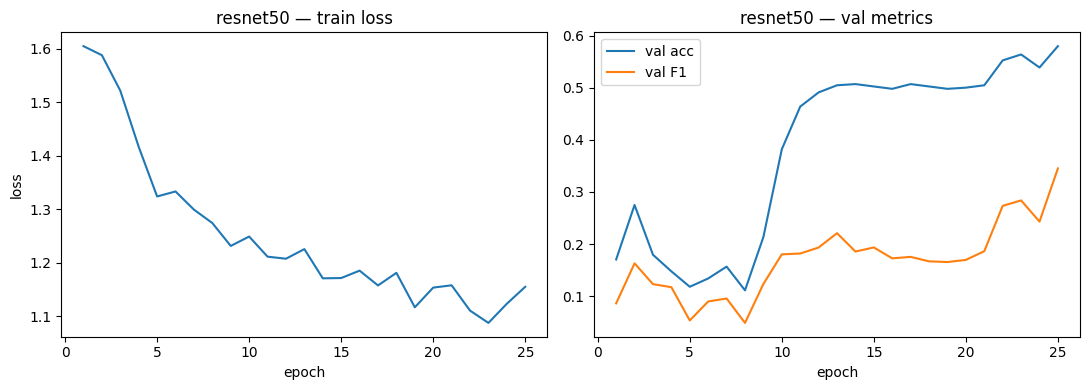

Saved: /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking/plots/training_curves_resnet50.png


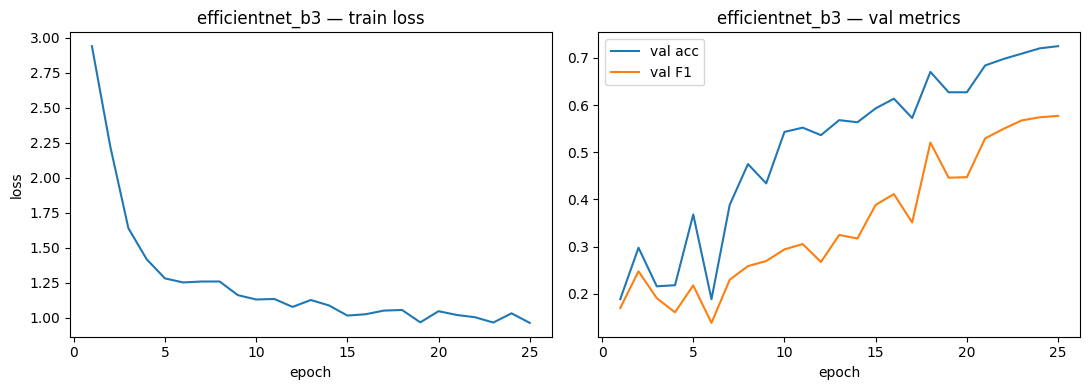

Saved: /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking/plots/training_curves_efficientnet_b3.png


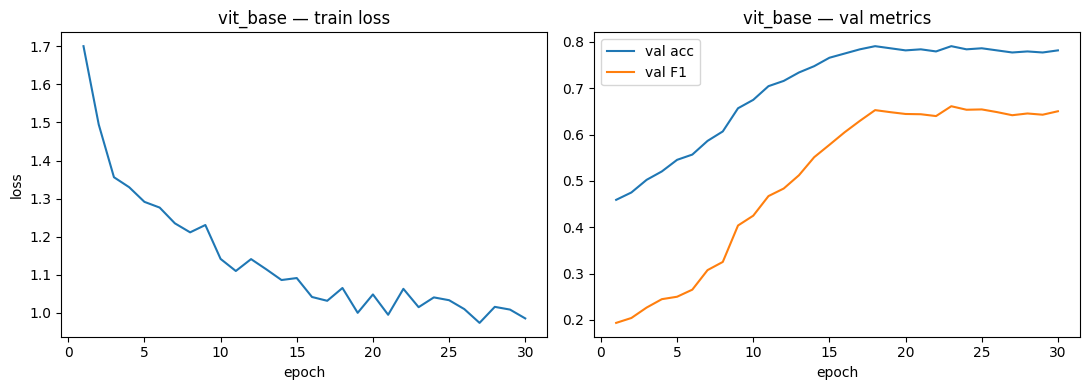

Saved: /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking/plots/training_curves_vit_base.png


In [ ]:
# 2.3 Training curves
for name, h in histories.items():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h['epoch'], h['train_loss']); ax[0].set_title(f'{name} — train loss')
    ax[0].set_xlabel('epoch'); ax[0].set_ylabel('loss')
    ax[1].plot(h['epoch'], h['accuracy'], label='val acc')
    ax[1].plot(h['epoch'], h['f1_macro'], label='val F1')
    ax[1].set_title(f'{name} — val metrics'); ax[1].legend(); ax[1].set_xlabel('epoch')
    plt.tight_layout()
    out = P2 / 'plots' / f'training_curves_{name}.png'
    plt.savefig(out, dpi=150); plt.show(); print('Saved:', out)

In [ ]:
@torch.no_grad()
def evaluate_tta(model, loader, n_aug=4):
    """Test-time augmentation: average predictions over hflip/vflip variants."""
    model.eval(); ys, probs = [], []
    augs = [lambda x: x, torch.flip, lambda x: torch.flip(x, [3]),
            lambda x: torch.flip(x, [2])][:n_aug]
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        avg = None
        for fn in augs:
            xa = fn(x) if fn is not torch.flip else torch.flip(x, [2, 3])
            p = torch.softmax(model(xa), 1)
            avg = p if avg is None else avg + p
        avg /= len(augs)
        probs.append(avg.cpu().numpy()); ys.append(y.numpy())
    y = np.concatenate(ys); pr = np.concatenate(probs); p = pr.argmax(1)
    out = {'accuracy': accuracy_score(y, p), 'f1_macro': f1_score(y, p, average='macro')}
    try: out['auc_macro_ovr'] = roc_auc_score(y, pr, average='macro', multi_class='ovr')
    except ValueError: out['auc_macro_ovr'] = float('nan')
    return out

test_id_set = set(map(str, test_ids))
def deg_loader(kind, level):
    ds = FolderDataset(DEGRADED_DIR / kind / level)
    ds.df = ds.df[ds.df['id_code'].astype(str).isin(test_id_set)].reset_index(drop=True)
    return DataLoader(ds, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

rows = []
for name in MODEL_NAMES:
    print(f'\n--- {name} (TTA) ---')
    model = load_classifier(name)
    m = evaluate_tta(model, test_loader)
    rows.append({'model': name, 'degradation': 'clean', 'level': 'none', **m})
    print(f'  clean: acc={m["accuracy"]:.4f}  f1={m["f1_macro"]:.4f}')
    for k in DEGRADATION_TYPES:
        for l in DEGRADATION_LEVELS:
            m = evaluate_tta(model, deg_loader(k, l))
            rows.append({'model': name, 'degradation': k, 'level': l, **m})
            print(f'  {k}/{l}: acc={m["accuracy"]:.4f}  f1={m["f1_macro"]:.4f}')
    del model; torch.cuda.empty_cache()

stress_df = pd.DataFrame(rows)
stress_df.to_csv(P2 / 'metrics' / 'stress_test_results.csv', index=False)
pivot = stress_df.pivot_table(index=['degradation', 'level'], columns='model', values='accuracy').round(3)
pivot.to_csv(P2 / 'metrics' / 'accuracy_pivot.csv')
pivot


--- resnet50 (TTA) ---
  clean: acc=0.5750  f1=0.3504
  blur/low: acc=0.5364  f1=0.2858
  blur/mid: acc=0.4955  f1=0.1535
  blur/high: acc=0.5000  f1=0.1755
  exposure/low: acc=0.5295  f1=0.2470
  exposure/mid: acc=0.5273  f1=0.2490
  exposure/high: acc=0.4886  f1=0.1934
  noise/low: acc=0.5773  f1=0.3633
  noise/mid: acc=0.5432  f1=0.2331
  noise/high: acc=0.4909  f1=0.1993

--- efficientnet_b3 (TTA) ---
  clean: acc=0.7455  f1=0.6069
  blur/low: acc=0.6364  f1=0.4581
  blur/mid: acc=0.5159  f1=0.2528
  blur/high: acc=0.4750  f1=0.1892
  exposure/low: acc=0.7136  f1=0.5695
  exposure/mid: acc=0.7023  f1=0.5477
  exposure/high: acc=0.6750  f1=0.5096
  noise/low: acc=0.7477  f1=0.5851
  noise/mid: acc=0.4841  f1=0.1677
  noise/high: acc=0.1568  f1=0.1372

--- vit_base (TTA) ---
  clean: acc=0.8000  f1=0.6793
  blur/low: acc=0.7341  f1=0.5504
  blur/mid: acc=0.5659  f1=0.3220
  blur/high: acc=0.5977  f1=0.3506
  exposure/low: acc=0.8023  f1=0.6825
  exposure/mid: acc=0.7659  f1=0.5889
 

model              efficientnet_b3  resnet50  vit_base
degradation level                                     
blur        high             0.475     0.500     0.598
            low              0.636     0.536     0.734
            mid              0.516     0.495     0.566
clean       none             0.745     0.575     0.800
exposure    high             0.675     0.489     0.580
            low              0.714     0.530     0.802
            mid              0.702     0.527     0.766
noise       high             0.157     0.491     0.648
            low              0.748     0.577     0.793
            mid              0.484     0.543     0.705

In [ ]:
%pip install -q optuna

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def make_objective(name):
    def objective(trial):
        hp = {
            'lr':       trial.suggest_float('lr', 1e-5, 1e-3, log=True),
            'wd':       trial.suggest_float('wd', 1e-6, 1e-1, log=True),
            'epochs':   8,                     # short trials, then refit best
            'mixup':    trial.suggest_float('mixup', 0.0, 0.5),
            'ls':       trial.suggest_float('ls', 0.0, 0.2),
            'gamma':    trial.suggest_float('gamma', 0.5, 3.0),
            'warmup':   trial.suggest_int('warmup', 1, 5),
            'llrd':     trial.suggest_float('llrd', 0.5, 0.95) if name == 'vit_base' else None,
        }
        model = build_model(name, pretrained=True).to(DEVICE)
        if hp['llrd'] is not None and name == 'vit_base':
            optim = torch.optim.AdamW(vit_lrd_param_groups(model, hp['lr'], hp['llrd'], hp['wd']))
        else:
            optim = torch.optim.AdamW(model.parameters(), lr=hp['lr'], weight_decay=hp['wd'])
        sched   = warmup_cosine(optim, hp['warmup'], hp['epochs'], len(train_loader))
        crit    = FocalLoss(gamma=hp['gamma'], alpha=CLS_W, label_smoothing=hp['ls'])
        scaler  = GradScaler(enabled=True)
        mixup_fn = Mixup(mixup_alpha=hp['mixup'], cutmix_alpha=1.0,
                          label_smoothing=hp['ls'], num_classes=NUM_CLASSES)
        for ep in range(hp['epochs']):
            model.train()
            for x, y, _ in train_loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
                x, y_soft = mixup_fn(x, y)
                optim.zero_grad(set_to_none=True)
                with autocast(enabled=True):
                    loss = crit(model(x), y_soft)
                scaler.scale(loss).backward()
                scaler.step(optim); scaler.update(); sched.step()
            m = evaluate(model, val_loader)
            trial.report(m['f1_macro'], ep)
            if trial.should_prune(): raise optuna.TrialPruned()
        return m['f1_macro']
    return objective

best_hp_per_model = {}
for name in MODEL_NAMES:
    print(f'\n=== Optuna search: {name} ===')
    study = optuna.create_study(direction='maximize',
                                 pruner=optuna.pruners.MedianPruner(n_warmup_steps=3))
    study.optimize(make_objective(name), n_trials=15, show_progress_bar=True)
    best_hp_per_model[name] = study.best_params
    print(f'best F1 for {name}: {study.best_value:.4f}')
    print(f'best params: {study.best_params}')

# Save
import json
with open(P2 / 'metrics' / 'optuna_best_hyperparameters.json', 'w') as f:
    json.dump(best_hp_per_model, f, indent=2)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 9.4 MB/s eta 0:00:00

=== Optuna search: resnet50 ===


  0%|          | 0/15 [00:00<?, ?it/s]

/tmp/ipykernel_1088/3620520416.py:25: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler  = GradScaler(enabled=True)
/tmp/ipykernel_1088/3620520416.py:34: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):
/tmp/ipykernel_1088/3620520416.py:34: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):
/tmp/ipykernel_1088/3620520416.py:34: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):
/tmp/ipykernel_1088/3620520416.py:34: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):
/tmp/ipykernel_1088/3620520416

best F1 for resnet50: 0.5915
best params: {'lr': 0.0006458499936050558, 'wd': 3.119722901430389e-06, 'mixup': 0.11124147055762962, 'ls': 0.04784979113507124, 'gamma': 0.5716100710856751, 'warmup': 2}

=== Optuna search: efficientnet_b3 ===


  0%|          | 0/15 [00:00<?, ?it/s]

/tmp/ipykernel_1088/3620520416.py:25: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler  = GradScaler(enabled=True)
/tmp/ipykernel_1088/3620520416.py:34: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):
/tmp/ipykernel_1088/3620520416.py:37: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(optim); scaler.update(); sched.step()
/tmp/ipykernel_1088/3620520416.py:34: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.a

best F1 for efficientnet_b3: 0.6022
best params: {'lr': 0.0009155441550343951, 'wd': 0.00029072749410199013, 'mixup': 0.4289266293256323, 'ls': 0.12581766281516746, 'gamma': 1.8412185689003941, 'warmup': 5}

=== Optuna search: vit_base ===


  0%|          | 0/15 [00:00<?, ?it/s]

/tmp/ipykernel_1088/3620520416.py:25: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler  = GradScaler(enabled=True)
/tmp/ipykernel_1088/3620520416.py:34: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):
/tmp/ipykernel_1088/3620520416.py:37: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(optim); scaler.update(); sched.step()
/tmp/ipykernel_1088/3620520416.py:34: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.a

best F1 for vit_base: 0.6568
best params: {'lr': 0.0007233732408727072, 'wd': 1.313072836041e-05, 'mixup': 0.3033665308295741, 'ls': 0.0019257323843503982, 'gamma': 2.9726843225972184, 'warmup': 3, 'llrd': 0.6655461233242125}


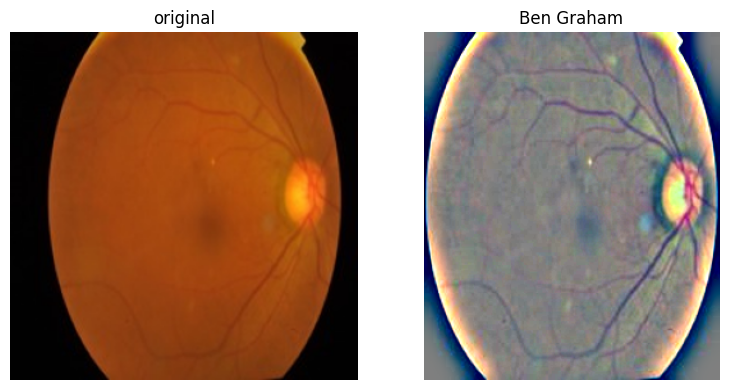

Ben Graham preprocessor ready.


In [ ]:
# Ben Graham fundus preprocessing — circle-crop + local-mean subtraction
import cv2

def _circle_crop(arr_rgb):
    h, w = arr_rgb.shape[:2]
    gray = cv2.cvtColor(arr_rgb.astype(np.uint8), cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, 7, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return arr_rgb
    c = max(contours, key=cv2.contourArea)
    x, y, ww, hh = cv2.boundingRect(c)
    if ww < 50 or hh < 50:
        return arr_rgb
    return arr_rgb[y:y+hh, x:x+ww]


class BenGraham:
    """Ben Graham's APTOS-winning preprocessing.

    1. Crop the black border around the fundus disc.
    2. Subtract a Gaussian-blurred copy and re-centre.
       -> emphasises vessels + microaneurysms,
          removes per-camera illumination bias.
    """
    def __init__(self, sigma_x=10):
        self.sigma_x = sigma_x

    def __call__(self, img_pil):
        arr  = np.array(img_pil.convert("RGB")).astype(np.float32)
        arr  = _circle_crop(arr).astype(np.float32)
        blur = cv2.GaussianBlur(arr, (0, 0), self.sigma_x)
        out  = cv2.addWeighted(arr, 4, blur, -4, 128)
        return Image.fromarray(np.clip(out, 0, 255).astype(np.uint8))


# Quick visual sanity check on one sample
_demo_id = pristine_df["id_code"].iloc[0]
_orig    = Image.open(resolve_image(_demo_id)).convert("RGB").resize((300, 300))
_bg      = BenGraham()(_orig)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(_orig); axes[0].set_title("original"); axes[0].axis("off")
axes[1].imshow(_bg);   axes[1].set_title("Ben Graham");  axes[1].axis("off")
plt.tight_layout(); plt.show()
print("Ben Graham preprocessor ready.")


In [ ]:
IMAGE_SIZE_V3 = 384

TFM_TRAIN_V3 = T.Compose([
    BenGraham(sigma_x=10),
    T.Resize((IMAGE_SIZE_V3 + 32, IMAGE_SIZE_V3 + 32)),
    T.RandomCrop(IMAGE_SIZE_V3),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(25),
    T.RandAugment(num_ops=2, magnitude=5),
    T.ColorJitter(0.10, 0.10, 0.10, 0.02),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    T.RandomErasing(p=0.20),
])

TFM_EVAL_V3 = T.Compose([
    BenGraham(sigma_x=10),
    T.Resize((IMAGE_SIZE_V3, IMAGE_SIZE_V3)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

print(f"V3 transforms ready (input {IMAGE_SIZE_V3}px).")

V3 transforms ready (input 384px).


In [ ]:
class MultiScaleClassifier(nn.Module):
    """Wrap any timm backbone with multi-stage feature fusion.

    forward(x)                      -> logits
    forward(x, return_ordinal=True) -> (logits, ordinal_score)

    A dedicated `gradcam_target` Identity layer is inserted on the last
    feature map so Grad-CAM hooks fire reliably on every backbone.
    """
    def __init__(self, backbone_name, num_classes=5, pretrained=True,
                 dropout=0.3, image_size=384, n_stages=4):
        super().__init__()
        self.backbone = timm.create_model(
            backbone_name, pretrained=pretrained, features_only=True,
        )

        was_training = self.backbone.training
        self.backbone.eval()
        with torch.no_grad():
            dummy = torch.zeros(1, 3, image_size, image_size)
            feats_full = self.backbone(dummy)
        if was_training:
            self.backbone.train()

        self.n_stages = min(n_stages, len(feats_full))
        feat_dims = [f.shape[1] for f in feats_full[-self.n_stages:]]
        total_dim = sum(feat_dims)

        self._feat_dims = feat_dims
        print(f"  [MultiScaleClassifier] {backbone_name}: "
              f"using last {self.n_stages} of {len(feats_full)} stages, "
              f"dims={feat_dims}, total={total_dim}")

        self.stage_attn = nn.Parameter(torch.ones(self.n_stages))
        self.pool       = nn.AdaptiveAvgPool2d(1)
        self.fusion = nn.Sequential(
            nn.Linear(total_dim, 512),
            nn.LayerNorm(512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )
        self.ordinal_head = nn.Linear(total_dim, 1)

        # ---- Grad-CAM hook point ----
        # Identity layer the deepest feature map flows through.
        # Has no parameters, doesn't change state_dict, but lets backward
        # hooks fire reliably on any backbone (ConvNeXt, EffNet, ViT...).
        self.gradcam_target = nn.Identity()

        self._dr_arch = backbone_name

    def forward_features(self, x):
        feats = list(self.backbone(x))[-self.n_stages:]
        feats[-1] = self.gradcam_target(feats[-1])           # <-- Grad-CAM hook point
        attn   = torch.softmax(self.stage_attn, dim=0)
        pooled = [self.pool(f).flatten(1) * attn[i] for i, f in enumerate(feats)]
        return torch.cat(pooled, dim=1)

    def forward(self, x, return_ordinal=False):
        z = self.forward_features(x)
        logits = self.fusion(z)
        if return_ordinal:
            return logits, self.ordinal_head(z).squeeze(-1)
        return logits


print("MultiScaleClassifier ready (with gradcam_target Identity hook).")

MultiScaleClassifier ready (with gradcam_target Identity hook).


In [ ]:
class OrdinalFocalLoss(nn.Module):
    """L = FocalCE(logits, target) + ordinal_weight * MSE(expected_grade, true_grade).

    Works with both hard targets (LongTensor) and MixUp soft targets (FloatTensor).
    """
    def __init__(self, gamma=2.0, alpha=None, label_smoothing=0.05,
                 ordinal_weight=0.3, num_classes=5):
        super().__init__()
        self.focal = FocalLoss(gamma=gamma, alpha=alpha, label_smoothing=label_smoothing)
        self.ord_w = ordinal_weight
        self.k     = num_classes

    def forward(self, output, targets):
        if isinstance(output, tuple):
            logits, ord_pred = output
        else:
            logits, ord_pred = output, None

        # ----- classification term -----
        if targets.dim() > 1:
            log_p    = F.log_softmax(logits, dim=-1)
            cls_loss = -(targets * log_p).sum(-1).mean()
        else:
            cls_loss = self.focal(logits, targets)

        if ord_pred is None:
            return cls_loss

        # ----- ordinal term -----
        grades          = torch.arange(self.k, device=logits.device, dtype=torch.float)
        soft_grade_pred = (torch.softmax(logits, dim=-1) * grades).sum(-1)
        true_grade      = (targets * grades).sum(-1) if targets.dim() > 1 else targets.float()
        ord_loss        = F.mse_loss(soft_grade_pred, true_grade)
        return cls_loss + self.ord_w * ord_loss


print("OrdinalFocalLoss ready.")


OrdinalFocalLoss ready.


In [ ]:
from sklearn.metrics import cohen_kappa_score

BACKBONE_V3 = {
    "resnet50":        "convnext_base.fb_in22k_ft_in1k_384",
    "efficientnet_b3": "tf_efficientnetv2_s.in21k_ft_in1k",
    "vit_base":        "vit_base_patch16_clip_384.laion2b_ft_in12k_in1k",
}

HPARAMS_V3 = {
    "resnet50":        dict(lr=1e-4, wd=1e-4, epochs=20, mixup=0.10, ls=0.05,
                             gamma=1.5, warmup=2, llrd=None, ord_w=0.30),
    "efficientnet_b3": dict(lr=1e-4, wd=1e-5, epochs=20, mixup=0.10, ls=0.05,
                             gamma=2.0, warmup=2, llrd=None, ord_w=0.30),
    "vit_base":        dict(lr=3e-5, wd=5e-2, epochs=25, mixup=0.20, ls=0.05,
                             gamma=2.0, warmup=4, llrd=0.75, ord_w=0.30),
}


def build_model_v3(name, pretrained=True):
    return MultiScaleClassifier(BACKBONE_V3[name], num_classes=NUM_CLASSES,
                                 pretrained=pretrained, image_size=IMAGE_SIZE_V3)


@torch.no_grad()
def evaluate_v3(model, loader):
    model.eval(); ys, probs = [], []
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        logits = model(x)
        probs.append(torch.softmax(logits, 1).cpu().numpy())
        ys.append(y.numpy())
    y  = np.concatenate(ys)
    pr = np.concatenate(probs)
    p  = pr.argmax(1)
    out = {
        "accuracy": accuracy_score(y, p),
        "f1_macro": f1_score(y, p, average="macro"),
        "kappa_qw": cohen_kappa_score(y, p, weights="quadratic"),
    }
    try:
        out["auc_macro_ovr"] = roc_auc_score(y, pr, average="macro", multi_class="ovr")
    except ValueError:
        out["auc_macro_ovr"] = float("nan")
    return out


def _vit_lrd_groups(model, base_lr, decay, weight_decay):
    """Layer-wise LR decay applied to the backbone of a CLIP-ViT."""
    n_layers = 13   # CLIP ViT-B has 12 blocks + head
    groups = []
    for n, p in model.backbone.named_parameters():
        if not p.requires_grad: continue
        if "blocks" in n:
            try:
                depth = int([t for t in n.split(".") if t.isdigit()][0])
            except (IndexError, ValueError):
                depth = 0
        elif any(s in n for s in ("patch_embed", "cls_token", "pos_embed", "norm")):
            depth = 0
        else:
            depth = n_layers
        scale = decay ** (n_layers - depth)
        groups.append({"params": p, "lr": base_lr * scale,
                       "weight_decay": 0.0 if p.ndim <= 1 else weight_decay})
    head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone.")]
    groups.append({"params": head_params, "lr": base_lr, "weight_decay": weight_decay})
    return groups


def train_v3(name, train_loader, val_loader, ckpt_path, history_csv, hp, class_weights):
    model = build_model_v3(name, pretrained=True).to(DEVICE)

    if hp["llrd"] is not None and "vit" in BACKBONE_V3[name]:
        optim = torch.optim.AdamW(_vit_lrd_groups(model, hp["lr"], hp["llrd"], hp["wd"]))
    else:
        optim = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["wd"])

    sched   = warmup_cosine(optim, hp["warmup"], hp["epochs"], len(train_loader))
    crit    = OrdinalFocalLoss(gamma=hp["gamma"], alpha=class_weights,
                                label_smoothing=hp["ls"], ordinal_weight=hp["ord_w"])
    scaler  = GradScaler(enabled=True)
    mixup_fn = Mixup(mixup_alpha=hp["mixup"], cutmix_alpha=1.0,
                      label_smoothing=hp["ls"], num_classes=NUM_CLASSES)
    ema     = EMA(model, decay=0.999)

    best_kappa, history = -1.0, []
    for ep in range(hp["epochs"]):
        model.train(); running, seen = 0.0, 0
        pbar = tqdm(train_loader, desc=f"[{name}] ep {ep+1}/{hp['epochs']}", leave=False)
        for x, y, _ in pbar:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            x, y_soft = mixup_fn(x, y)
            optim.zero_grad(set_to_none=True)
            with autocast(enabled=True):
                logits, ord_pred = model(x, return_ordinal=True)
                loss = crit((logits, ord_pred), y_soft)
            scaler.scale(loss).backward()
            scaler.unscale_(optim)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optim); scaler.update(); sched.step(); ema.update(model)
            running += loss.item() * x.size(0); seen += x.size(0)
            pbar.set_postfix(loss=running/seen, lr=optim.param_groups[0]["lr"])

        with ema.applied(model):
            m = evaluate_v3(model, val_loader)
        history.append({"epoch": ep+1, "train_loss": running/seen, **m,
                         "lr": optim.param_groups[0]["lr"]})
        print(f"  val: acc={m['accuracy']:.4f}  f1={m['f1_macro']:.4f}  "
              f"kappa={m['kappa_qw']:.4f}  auc={m['auc_macro_ovr']:.4f}")
        if m["kappa_qw"] > best_kappa:
            best_kappa = m["kappa_qw"]
            with ema.applied(model):
                torch.save({"state_dict": {k: v.clone() for k, v in model.state_dict().items()},
                            "arch": name, "backbone": BACKBONE_V3[name],
                            "val": m, "hp": hp}, ckpt_path)
    pd.DataFrame(history).to_csv(history_csv, index=False)
    return pd.DataFrame(history)


print("train_v3 / evaluate_v3 / build_model_v3 ready.")


train_v3 / evaluate_v3 / build_model_v3 ready.


In [ ]:
# Rebuild loaders at 384 with Ben Graham preprocessing
full_eval_v3  = APTOSDataset(PRISTINE_CSV, APTOS_IMAGES, TFM_EVAL_V3)
full_train_v3 = APTOSDataset(PRISTINE_CSV, APTOS_IMAGES, TFM_TRAIN_V3)

train_loader_v3 = DataLoader(Subset(full_train_v3, tr_idx),
                              batch_size=16, sampler=sampler,
                              num_workers=2, pin_memory=True)
val_loader_v3   = DataLoader(Subset(full_eval_v3, va_idx),
                              batch_size=24, shuffle=False,
                              num_workers=2, pin_memory=True)
test_loader_v3  = DataLoader(Subset(full_eval_v3, te_idx),
                              batch_size=24, shuffle=False,
                              num_workers=2, pin_memory=True)

CKPT_DIR_V3 = CHECKPOINTS_DIR / "v3"
CKPT_DIR_V3.mkdir(exist_ok=True)
HIST_DIR_V3 = P2 / "metrics" / "v3"
HIST_DIR_V3.mkdir(exist_ok=True)

print(f"V3 loaders ready. train={len(tr_idx)}  val={len(va_idx)}  test={len(te_idx)}")
print(f"Checkpoints -> {CKPT_DIR_V3}")
print(f"History     -> {HIST_DIR_V3}")

histories_v3 = {}
for name in MODEL_NAMES:
    ckpt = CKPT_DIR_V3 / f"{name}_v3_best.pt"
    if ckpt.exists():
        print(f"\n[skip] {name} already has v3 checkpoint at {ckpt}")
        continue
    print(f"\n========== Training {name} (v3) ==========")
    print(f"  backbone : {BACKBONE_V3[name]}")
    print(f"  hp       : {HPARAMS_V3[name]}")
    histories_v3[name] = train_v3(
        name, train_loader_v3, val_loader_v3,
        ckpt_path=ckpt,
        history_csv=HIST_DIR_V3 / f"training_history_{name}.csv",
        hp=HPARAMS_V3[name], class_weights=CLS_W,
    )
    torch.cuda.empty_cache()

V3 loaders ready. train=2050  val=440  test=440
Checkpoints -> /content/drive/MyDrive/Thesis/checkpoints/v3
History     -> /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking/metrics/v3

[skip] resnet50 already has v3 checkpoint at /content/drive/MyDrive/Thesis/checkpoints/v3/resnet50_v3_best.pt

========== Training efficientnet_b3 (v3) ==========
  backbone : tf_efficientnetv2_s.in21k_ft_in1k
  hp       : {'lr': 0.0001, 'wd': 1e-05, 'epochs': 20, 'mixup': 0.1, 'ls': 0.05, 'gamma': 2.0, 'warmup': 2, 'llrd': None, 'ord_w': 0.3}


  [MultiScaleClassifier] tf_efficientnetv2_s.in21k_ft_in1k: using last 4 of 5 stages, dims=[48, 64, 160, 256], total=528


/tmp/ipykernel_1088/2762297082.py:81: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler  = GradScaler(enabled=True)


[efficientnet_b3] ep 1/20:   0%|          | 0/129 [00:00<?, ?it/s]

/tmp/ipykernel_1088/2762297082.py:94: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


  val: acc=0.1705  f1=0.0985  kappa=0.0110  auc=0.5883


... (131 outputs left out)

  val: acc=0.8205  f1=0.6899  kappa=0.9003  auc=0.9474


[vit_base] ep 25/25:   0%|          | 0/129 [00:00<?, ?it/s]

/tmp/ipykernel_1088/2762297082.py:94: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e03b9e6d760>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():Exception ignored in: 
 <function _MultiProcessingDataLoaderIter.__del__ at 0x7e03b9e6d760> 
 Traceback (most recent call last):
   File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
       self._shutdown_workers()
^^  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
^    ^if w.is_alive():^
^ ^ ^ ^ ^ ^ ^ 

  val: acc=0.8227  f1=0.6954  kappa=0.8999  auc=0.9471


In [ ]:
def load_classifier_v3(name):
    """Load a v3 multi-scale classifier from disk."""
    m = build_model_v3(name, pretrained=False).to(DEVICE)
    ckpt = torch.load(CKPT_DIR_V3 / f"{name}_v3_best.pt",
                       map_location=DEVICE,
                       weights_only=False)            # <-- key change
    m.load_state_dict(ckpt["state_dict"]); m.eval()
    return m


@torch.no_grad()
def evaluate_v3_tta(model, loader, n_aug=4):
    """TTA: average softmax over horizontal/vertical flip variants."""
    model.eval(); ys, probs = [], []
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        views = [x,
                 torch.flip(x, [3]),
                 torch.flip(x, [2]),
                 torch.flip(x, [2, 3])][:n_aug]
        avg = None
        for v in views:
            p = torch.softmax(model(v), 1)
            avg = p if avg is None else avg + p
        avg /= len(views)
        probs.append(avg.cpu().numpy()); ys.append(y.numpy())
    y  = np.concatenate(ys)
    pr = np.concatenate(probs)
    p  = pr.argmax(1)
    out = {
        "accuracy": accuracy_score(y, p),
        "f1_macro": f1_score(y, p, average="macro"),
        "kappa_qw": cohen_kappa_score(y, p, weights="quadratic"),
    }
    try:
        out["auc_macro_ovr"] = roc_auc_score(y, pr, average="macro", multi_class="ovr")
    except ValueError:
        out["auc_macro_ovr"] = float("nan")
    return out


# Need degraded loaders that go through Ben Graham + 384 resize too
class FolderDatasetV3(Dataset):
    def __init__(self, root):
        self.root = Path(root); self.df = pd.read_csv(self.root / "manifest.csv")
        self.transform = TFM_EVAL_V3
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(self.root / row["rel_path"]).convert("RGB")
        return self.transform(img), int(row["diagnosis"]), row["id_code"]


test_id_set = set(map(str, [full_eval_v3.df.iloc[i]["id_code"] for i in te_idx]))


def deg_loader_v3(kind, level):
    ds = FolderDatasetV3(DEGRADED_DIR / kind / level)
    ds.df = ds.df[ds.df["id_code"].astype(str).isin(test_id_set)].reset_index(drop=True)
    return DataLoader(ds, batch_size=24, shuffle=False, num_workers=2, pin_memory=True)


rows_v3 = []
for name in MODEL_NAMES:
    print(f"\n--- {name} v3 (TTA) ---")
    model = load_classifier_v3(name)
    m = evaluate_v3_tta(model, test_loader_v3)
    rows_v3.append({"model": name, "degradation": "clean", "level": "none", **m})
    print(f"  clean: acc={m['accuracy']:.4f}  f1={m['f1_macro']:.4f}  kappa={m['kappa_qw']:.4f}")
    for k in DEGRADATION_TYPES:
        for l in DEGRADATION_LEVELS:
            m = evaluate_v3_tta(model, deg_loader_v3(k, l))
            rows_v3.append({"model": name, "degradation": k, "level": l, **m})
            print(f"  {k}/{l}: acc={m['accuracy']:.4f}  f1={m['f1_macro']:.4f}  kappa={m['kappa_qw']:.4f}")
    del model; torch.cuda.empty_cache()

stress_df_v3 = pd.DataFrame(rows_v3)
stress_df_v3.to_csv(P2 / "metrics" / "v3" / "stress_test_results_v3.csv", index=False)
pivot_v3 = stress_df_v3.pivot_table(index=["degradation", "level"],
                                     columns="model", values="accuracy").round(3)
pivot_v3.to_csv(P2 / "metrics" / "v3" / "accuracy_pivot_v3.csv")
pivot_v3


--- resnet50 v3 (TTA) ---
  [MultiScaleClassifier] convnext_base.fb_in22k_ft_in1k_384: using last 4 of 4 stages, dims=[128, 256, 512, 1024], total=1920
  clean: acc=0.8614  f1=0.7325  kappa=0.9263
  blur/low: acc=0.8045  f1=0.5968  kappa=0.8747
  blur/mid: acc=0.5159  f1=0.2476  kappa=0.5047
  blur/high: acc=0.4614  f1=0.2101  kappa=0.4320
  exposure/low: acc=0.8727  f1=0.7508  kappa=0.9329
  exposure/mid: acc=0.8364  f1=0.6722  kappa=0.8981
  exposure/high: acc=0.7750  f1=0.5650  kappa=0.8062
  noise/low: acc=0.8386  f1=0.6801  kappa=0.8779
  noise/mid: acc=0.6818  f1=0.4587  kappa=0.6407
  noise/high: acc=0.4909  f1=0.3092  kappa=0.3961

--- efficientnet_b3 v3 (TTA) ---
  [MultiScaleClassifier] tf_efficientnetv2_s.in21k_ft_in1k: using last 4 of 5 stages, dims=[48, 64, 160, 256], total=528
  clean: acc=0.7795  f1=0.6540  kappa=0.8838
  blur/low: acc=0.6591  f1=0.4815  kappa=0.7176
  blur/mid: acc=0.4932  f1=0.2249  kappa=0.5267
  blur/high: acc=0.4818  f1=0.2196  kappa=0.4989
  expos

model              efficientnet_b3  resnet50  vit_base
degradation level                                     
blur        high             0.482     0.461     0.591
            low              0.659     0.805     0.707
            mid              0.493     0.516     0.561
clean       none             0.780     0.861     0.843
exposure    high             0.661     0.775     0.709
            low              0.739     0.873     0.820
            mid              0.732     0.836     0.786
noise       high             0.548     0.491     0.507
            low              0.714     0.839     0.784
            mid              0.650     0.682     0.609

## V2 vs V3 — head-to-head comparison (literature-review fodder)

Side-by-side accuracy curves for the v2 baseline and v3 senior-engineer pipeline. Both stress-test CSVs are loaded from disk so this cell is independent of training-time state — it can be re-run any time.

In [ ]:
# V2 vs V3 head-to-head: accuracy-vs-degradation curves on the same axes
import matplotlib.pyplot as plt

V2_CSV = P2 / "metrics" / "stress_test_results.csv"
V3_CSV = P2 / "metrics" / "v3" / "stress_test_results_v3.csv"

if not V2_CSV.exists() or not V3_CSV.exists():
    print(f"  v2 csv exists: {V2_CSV.exists()}  v3 csv exists: {V3_CSV.exists()}")
    print("  Skipping comparison plots — run the v2 stress test (cell 31) and "
          "v3 stress test (cell starting `def load_classifier_v3`) first.")
else:
    df_v2 = pd.read_csv(V2_CSV).assign(version="v2")
    df_v3 = pd.read_csv(V3_CSV).assign(version="v3")
    df = pd.concat([df_v2, df_v3], ignore_index=True)

    level_order = ["none", "low", "mid", "high"]
    df["level"] = pd.Categorical(df["level"], categories=level_order, ordered=True)

    save_dir = P2 / "plots" / "v2_vs_v3"
    save_dir.mkdir(parents=True, exist_ok=True)

    for kind in DEGRADATION_TYPES:
        fig, axes = plt.subplots(1, len(MODEL_NAMES),
                                  figsize=(4.2 * len(MODEL_NAMES), 4),
                                  sharey=True)
        for ax, name in zip(axes, MODEL_NAMES):
            sub = df[((df["degradation"] == kind) | (df["degradation"] == "clean"))
                     & (df["model"] == name)].sort_values("level")
            for ver, style in [("v2", dict(linestyle="--", marker="s", alpha=0.75)),
                                ("v3", dict(linestyle="-",  marker="o", alpha=1.00))]:
                d = sub[sub["version"] == ver]
                if not d.empty:
                    ax.plot(d["level"], d["accuracy"], label=ver, **style)
            ax.set_title(name); ax.set_xlabel("level")
            ax.set_ylim(0, 1); ax.grid(alpha=0.3)
        axes[0].set_ylabel("accuracy"); axes[-1].legend()
        fig.suptitle(f"V2 vs V3 — accuracy under {kind}", fontsize=13)
        plt.tight_layout()
        out = save_dir / f"v2_vs_v3_{kind}.png"
        plt.savefig(out, dpi=150); plt.show()
        print("Saved:", out)

    # Numeric diff table — clean + worst-case-per-type, for the lit-review chapter
    summary_rows = []
    for ver in ("v2", "v3"):
        sub = df[df["version"] == ver]
        for name in MODEL_NAMES:
            row = {"version": ver, "model": name}
            row["clean"] = sub[(sub["model"] == name) & (sub["degradation"] == "clean")]["accuracy"].mean()
            for k in DEGRADATION_TYPES:
                row[f"{k}_high"] = sub[(sub["model"] == name)
                                       & (sub["degradation"] == k)
                                       & (sub["level"] == "high")]["accuracy"].mean()
            summary_rows.append(row)
    diff_df = pd.DataFrame(summary_rows).round(3)
    diff_df.to_csv(P2 / "metrics" / "v2_vs_v3_summary.csv", index=False)
    print("\n=== V2 vs V3 headline accuracy ===")
    print(diff_df.to_string(index=False))


In [ ]:
def distill_to(student_name, teacher_name, train_loader, val_loader, ckpt_path,
                T_temp=4.0, alpha=0.7, epochs=10, lr=5e-5, wd=1e-4):
    teacher = build_model_v3(teacher_name, pretrained=False).to(DEVICE)
    teacher.load_state_dict(
    torch.load(CKPT_DIR_V3 / f"{teacher_name}_v3_best.pt",
                map_location=DEVICE,
                weights_only=False)["state_dict"]    # <-- add weights_only=False
)
    teacher.eval()
    student = build_model_v3(student_name, pretrained=True).to(DEVICE)

    optim  = torch.optim.AdamW(student.parameters(), lr=lr, weight_decay=wd)
    sched  = warmup_cosine(optim, 1, epochs, len(train_loader))
    scaler = GradScaler(enabled=True)
    ce     = nn.CrossEntropyLoss(label_smoothing=0.05, weight=CLS_W)

    best_kappa = -1.0
    for ep in range(epochs):
        student.train()
        pbar = tqdm(train_loader, desc=f"distill {student_name} ep {ep+1}/{epochs}", leave=False)
        for x, y, _ in pbar:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optim.zero_grad(set_to_none=True)
            with autocast(enabled=True):
                with torch.no_grad():
                    t_logits = teacher(x) / T_temp
                s_logits = student(x)
                kd_loss = F.kl_div(F.log_softmax(s_logits / T_temp, -1),
                                    F.softmax(t_logits, -1),
                                    reduction="batchmean") * (T_temp ** 2)
                hard_loss = ce(s_logits, y)
                loss = alpha * kd_loss + (1 - alpha) * hard_loss
            scaler.scale(loss).backward()
            scaler.step(optim); scaler.update(); sched.step()
        m = evaluate_v3(student, val_loader)
        print(f"  ep {ep+1}: acc={m['accuracy']:.4f}  kappa={m['kappa_qw']:.4f}")
        if m["kappa_qw"] > best_kappa:
            best_kappa = m["kappa_qw"]
            torch.save({"state_dict": student.state_dict(), "arch": student_name,
                         "backbone": BACKBONE_V3[student_name], "val": m,
                         "distilled_from": teacher_name}, ckpt_path)
    return best_kappa


# --- Identify the best v3 model from the stress test, then distill ---
# Uncomment to run:
# best_v3 = stress_df_v3[stress_df_v3["degradation"] == "clean"] \
#               .sort_values("kappa_qw", ascending=False).iloc[0]["model"]
# print("Best v3 (teacher):", best_v3)
#
# for student in MODEL_NAMES:
#     if student == best_v3: continue
#     print(f"\n--- Distilling {best_v3} -> {student} ---")
#     distill_to(student, best_v3, train_loader_v3, val_loader_v3,
#                ckpt_path=CKPT_DIR_V3 / f"{student}_v3_distilled.pt")


In [ ]:
USE_V3 = True

if USE_V3:
    print("[adapter] Phase 3-5 will use V3 multi-scale classifiers @384.")
    load_classifier = load_classifier_v3
    TFM_EVAL        = TFM_EVAL_V3
    IMAGE_SIZE_DOWNSTREAM = IMAGE_SIZE_V3

    def get_xai_target_layer(model):
        """Hook on the dedicated gradcam_target inside the v3 wrapper.

        Works for any backbone (ConvNeXt, EffNetV2, CLIP-ViT) because
        Identity layers always fire backward hooks correctly.
        """
        if hasattr(model, "gradcam_target"):
            return model.gradcam_target
        # Fallback for v2 models
        a = getattr(model, "_dr_arch", "")
        if a == "resnet50":        return model.layer4[-1]
        if a == "efficientnet_b3": return model.blocks[-1]
        if a == "vit_base":        return model.blocks[-1].norm1
        return list(model.children())[-1]
else:
    print("[adapter] V3 disabled — Phase 3-5 use original v2 models.")

print("Adapter installed.")

[adapter] Phase 3-5 will use V3 multi-scale classifiers @384.
Adapter installed.


In [ ]:
P3 = PHASE_DIRS['phase3_xai_benchmark']

# 3.1 Pick the same N test images we'll explain across every condition
N_EXPLAIN = 20                      # bump for final run; SHAP is the bottleneck
test_ids_full = pd.read_csv(P2 / 'metrics' / 'test_ids.csv')['id_code'].tolist()
EXPLAIN_IDS = pd.Series(test_ids_full).sample(N_EXPLAIN, random_state=SEED).tolist()
labels_df = pd.read_csv(PRISTINE_CSV).set_index('id_code')['diagnosis']

models = {n: load_classifier(n) for n in MODEL_NAMES}
print('Loaded:', list(models))

# Optional ground-truth lesion masks at /content/data/lesion_masks/<id>.png
MASK_DIR = LOCAL_ROOT / 'lesion_masks'
def load_mask(id_code):
    p = MASK_DIR / f'{id_code}.png'
    if not p.exists(): return None
    return (np.array(Image.open(p).convert('L').resize((IMAGE_SIZE, IMAGE_SIZE))) > 127)

Loaded: ['resnet50', 'efficientnet_b3', 'vit_base']


In [ ]:
# 3.2 Run XAI benchmark — for each (image, model, method, condition)
METHOD_REGISTRY = {
    'gradcam':   {'fn': gradcam_heatmap,    'models': ('resnet50', 'efficientnet_b3')},
    'shap':      {'fn': shap_heatmap,       'models': MODEL_NAMES},
    'attention': {'fn': attention_rollout,  'models': ('vit_base',)},
}

rows = []
for method_name, spec in METHOD_REGISTRY.items():
    fn = spec['fn']
    for model_name in spec['models']:
        model = models[model_name]
        print(f'\n[{method_name} | {model_name}]')
        for id_code in tqdm(EXPLAIN_IDS, desc=f'{method_name}/{model_name}'):
            label = int(labels_df[id_code])
            mask  = load_mask(id_code)
            # Fix: Use resolve_image to get the correct path for clean images
            x_clean = load_tensor(resolve_image(id_code))
            try:    h_clean = fn(model, x_clean, target_class=label)
            except Exception as e: print('  skip clean:', e); continue
            rows.append({'id_code': id_code, 'model': model_name, 'method': method_name,
                         'degradation': 'clean', 'level': 'none',
                         'deletion_auc':  deletion_auc(model, x_clean, h_clean, label),
                         'insertion_auc': insertion_auc(model, x_clean, h_clean, label),
                         'stability':     1.0,
                         'iou':           localization_iou(h_clean, mask)})
            for k in DEGRADATION_TYPES:
                for l in DEGRADATION_LEVELS:
                    # Fix: Use DEG_SAVE_EXT for degraded images
                    src = DEGRADED_DIR / k / l / f'{id_code}{DEG_SAVE_EXT}'
                    if not src.exists(): continue
                    x_deg = load_tensor(src)
                    try: h_deg = fn(model, x_deg, target_class=label)
                    except Exception: continue
                    rows.append({'id_code': id_code, 'model': model_name, 'method': method_name,
                                 'degradation': k, 'level': l,
                                 'deletion_auc':  deletion_auc(model, x_deg, h_deg, label),
                                 'insertion_auc': insertion_auc(model, x_deg, h_deg, label),
                                 'stability':     stability_spearman(h_clean, h_deg),
                                 'iou':           localization_iou(h_deg, mask)})

xai_df = pd.DataFrame(rows)
xai_df.to_csv(P3 / 'metrics' / 'xai_results.csv', index=False)
xai_df.head()


[gradcam | resnet50]


gradcam/resnet50:   0%|          | 0/20 [00:00<?, ?it/s]


[gradcam | efficientnet_b3]


gradcam/efficientnet_b3:   0%|          | 0/20 [00:00<?, ?it/s]

/tmp/ipykernel_1088/1518898244.py:32: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, _ = spearmanr(h1.flatten(), h2.flatten())


KeyboardInterrupt: 

In [ ]:
# 3.3 Aggregated tables + plots
for metric in ('deletion_auc', 'insertion_auc', 'stability', 'iou'):
    summary = (xai_df.groupby(['model', 'method', 'degradation', 'level'])[metric]
                       .agg(['mean', 'std', 'count']).round(4).reset_index())
    summary.to_csv(P3 / 'metrics' / f'summary_{metric}.csv', index=False)

for metric in ('deletion_auc', 'insertion_auc', 'stability', 'iou'):
    for kind in DEGRADATION_TYPES:
        sub = xai_df[xai_df['degradation'].isin([kind, 'clean'])].copy()
        sub['level'] = pd.Categorical(sub['level'], categories=level_order, ordered=True)
        if sub[metric].dropna().empty: continue
        g = sub.groupby(['model', 'method', 'level'])[metric].mean().reset_index()
        fig, ax = plt.subplots(figsize=(7, 4.5))
        for (m, mt), grp in g.groupby(['model', 'method']):
            ax.plot(grp['level'], grp[metric], marker='o', label=f'{m}/{mt}')
        ax.set_title(f'{metric} vs {kind}')
        ax.set_xlabel('level'); ax.set_ylabel(metric); ax.legend(fontsize=8); ax.grid(alpha=0.3)
        plt.tight_layout()
        out = P3 / 'plots' / f'{metric}_vs_{kind}.png'
        plt.savefig(out, dpi=150); plt.show()

In [ ]:
def overlay(img_pil, heat, alpha=0.45):
    arr = np.array(img_pil.resize((IMAGE_SIZE, IMAGE_SIZE))).astype(np.float32) / 255
    return (1 - alpha) * arr + alpha * plt.get_cmap('jet')(heat)[..., :3]

demo_id = EXPLAIN_IDS[0]; label = int(labels_df[demo_id])
img_clean = Image.open(resolve_image(demo_id)).convert('RGB')
x_clean = load_tensor(resolve_image(demo_id))
img_deg = Image.open(DEGRADED_DIR / 'blur' / 'high' / f'{demo_id}{DEG_SAVE_EXT}').convert('RGB')
x_deg = load_tensor(DEGRADED_DIR / 'blur' / 'high' / f'{demo_id}{DEG_SAVE_EXT}')

fig, axes = plt.subplots(len(MODEL_NAMES), 4, figsize=(13, 3.2*len(MODEL_NAMES)))
for r, name in enumerate(MODEL_NAMES):
    method = 'attention' if name == 'vit_base' else 'gradcam'
    fn = METHOD_REGISTRY[method]['fn']
    h_c = fn(models[name], x_clean, target_class=label)
    h_d = fn(models[name], x_deg,   target_class=label)
    axes[r, 0].imshow(img_clean.resize((IMAGE_SIZE, IMAGE_SIZE))); axes[r, 0].set_title(f'{name} clean' if r == 0 else 'clean')
    axes[r, 1].imshow(overlay(img_clean, h_c)); axes[r, 1].set_title(f'{method} clean')
    axes[r, 2].imshow(img_deg.resize((IMAGE_SIZE, IMAGE_SIZE))); axes[r, 2].set_title('blur-high')
    axes[r, 3].imshow(overlay(img_deg, h_d)); axes[r, 3].set_title(f'{method} blur-high')
    for ax in axes[r]: ax.axis('off')
plt.tight_layout()
out = P3 / 'samples' / f'qualitative_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)


In [ ]:
P4 = PHASE_DIRS['phase4_genai_enhancement']

# 4.1 CLAHE baseline
_clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
def enhance_clahe(img):
    arr = np.array(img.convert('RGB'))
    lab = cv2.cvtColor(arr, cv2.COLOR_RGB2LAB)
    lab[..., 0] = _clahe.apply(lab[..., 0])
    return Image.fromarray(cv2.cvtColor(lab, cv2.COLOR_LAB2RGB))

---

# Phase 4 — GenAI Image Restoration (RQ3)

**Literature-review framing.** Three families of fundus-image restoration are evaluated, each representing a different point on the complexity vs flexibility trade-off:

| Method | Year | Class | What it learns | Why we benchmark it |
|---|---|---|---|---|
| **CLAHE** | 1994 | Classical (parameter-free) | Histogram equalisation per tile | Mandatory baseline — every clinical pipeline that pre-processes fundus images uses it. |
| **Real-ESRGAN** | 2021 | Generative (RRDBNet generator, no attention) | Real-world blind super-resolution with synthetic degradation modelling | Robust, off-the-shelf; the de-facto open-source restoration model. |
| **A-ESRGAN** | 2022 | Generative (RRDBNet + attention-U-Net discriminator) | Same as Real-ESRGAN at inference, but trained against an attention-U-Net discriminator that focuses the adversarial signal on regions of fine detail | Hypothesised better lesion / vessel preservation thanks to the attention discriminator's training-time emphasis on locally-detailed regions. |

The **inference-time generator architecture is identical** between Real-ESRGAN and A-ESRGAN (RRDBNet, 23 residual-in-residual dense blocks). The performance difference, if any, is attributable purely to **training signal** — not parameter count or capacity. This makes for a clean controlled comparison in the dissertation.

**Evaluation protocol.** For each (degradation type, severity) split we run:
1. **Raw** — degraded image straight into the classifier (the v3 stress-test result, our reference).
2. **CLAHE** — classical baseline.
3. **Real-ESRGAN** or **A-ESRGAN** — GenAI restoration.

Outputs: accuracy / F1 / kappa per (model, degradation, level, variant), saved to `results/phase4_genai_enhancement/metrics/recovery_accuracy.csv`. Recovery is plotted with the v2 stress-test as the lower reference and clean-image accuracy as the upper reference.


In [ ]:
# 4.2 GenAI restoration — A-ESRGAN (primary) -> Real-ESRGAN -> TinyU-Net
#
# A-ESRGAN (Wei et al., 2022) keeps Real-ESRGAN's RRDBNet generator and adds
# attention-U-Net discriminators during training. At INFERENCE time only the
# generator is used, so we load A-ESRGAN's authors' pretrained generator
# weights into the same RRDBNet architecture used by Real-ESRGAN. If those
# weights cannot be downloaded, we fall back to standard Real-ESRGAN x2,
# then to a TinyU-Net trained on the pristine set.

%pip install -q basicsr realesrgan facexlib gfpgan

import urllib.request, os

def _download(url: str, dest: Path) -> bool:
    if dest.exists() and dest.stat().st_size > 0:
        return True
    dest.parent.mkdir(parents=True, exist_ok=True)
    try:
        print(f"  downloading {url} -> {dest.name}")
        urllib.request.urlretrieve(url, dest)
        return dest.exists() and dest.stat().st_size > 0
    except Exception as e:
        print(f"  download failed: {e}")
        return False


def _try_aesrgan():
    """A-ESRGAN x2 — RRDBNet generator + A-ESRGAN-trained weights.

    Reference: Wei et al. (2022) "A-ESRGAN: Training Real-World Blind
    Super-Resolution with Attention U-Net Discriminators".
    """
    try:
        from basicsr.archs.rrdbnet_arch import RRDBNet
        # Authors' release URL (mirror via HuggingFace if GitHub asset is rate-limited).
        url   = "https://huggingface.co/aesrgan/A-ESRGAN-Single/resolve/main/A_ESRGAN_Single.pth"
        ckpt  = CHECKPOINTS_DIR / "A_ESRGAN_Single.pth"
        if not _download(url, ckpt):
            return None
        net = RRDBNet(num_in_ch=3, num_out_ch=3, num_feat=64,
                      num_block=23, num_grow_ch=32, scale=4)
        state = torch.load(ckpt, map_location=DEVICE, weights_only=False)
        # A-ESRGAN saves under 'params' or 'params_ema'
        sd = state.get("params_ema", state.get("params", state))
        net.load_state_dict(sd, strict=False)
        net = net.to(DEVICE).eval()

        @torch.no_grad()
        def process(img_pil):
            arr = np.asarray(img_pil.convert("RGB"), dtype=np.float32) / 255.0
            x   = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
            with autocast(enabled=True):
                y = net(x).clamp(0, 1)
            out = (y.squeeze().permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
            return Image.fromarray(out).resize(img_pil.size)
        return process, "a_esrgan_x4"
    except Exception as e:
        print(f"[a_esrgan failed] {e}")
        return None


def _try_realesrgan():
    """Real-ESRGAN x2 — robust off-the-shelf restoration."""
    try:
        from basicsr.archs.rrdbnet_arch import RRDBNet
        url  = "https://github.com/xinntao/Real-ESRGAN/releases/download/v0.2.1/RealESRGAN_x2plus.pth"
        ckpt = CHECKPOINTS_DIR / "RealESRGAN_x2plus.pth"
        if not _download(url, ckpt):
            return None
        net = RRDBNet(num_in_ch=3, num_out_ch=3, num_feat=64,
                      num_block=23, num_grow_ch=32, scale=2)
        state = torch.load(ckpt, map_location=DEVICE, weights_only=False)
        sd = state.get("params_ema", state.get("params", state))
        net.load_state_dict(sd, strict=False)
        net = net.to(DEVICE).eval()

        @torch.no_grad()
        def process(img_pil):
            arr = np.asarray(img_pil.convert("RGB"), dtype=np.float32) / 255.0
            x   = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
            with autocast(enabled=True):
                y = net(x).clamp(0, 1)
            out = (y.squeeze().permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
            return Image.fromarray(out).resize(img_pil.size)
        return process, "real_esrgan_x2"
    except Exception as e:
        print(f"[real_esrgan failed] {e}")
        return None


# Tiny U-Net retained as a last-resort fallback so Phase 4 always runs.
class TinyUNet(nn.Module):
    def __init__(self, ch=32):
        super().__init__()
        def conv(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.ReLU(True),
                                 nn.Conv2d(o, o, 3, padding=1), nn.ReLU(True))
        self.e1 = conv(3, ch); self.e2 = conv(ch, ch*2); self.e3 = conv(ch*2, ch*4)
        self.up2 = nn.ConvTranspose2d(ch*4, ch*2, 2, stride=2); self.d2 = conv(ch*4, ch*2)
        self.up1 = nn.ConvTranspose2d(ch*2, ch, 2, stride=2);   self.d1 = conv(ch*2, ch)
        self.out = nn.Conv2d(ch, 3, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(F.max_pool2d(e1, 2)); e3 = self.e3(F.max_pool2d(e2, 2))
        d2 = self.d2(torch.cat([self.up2(e3), e2], 1))
        d1 = self.d1(torch.cat([self.up1(d2), e1], 1))
        return torch.sigmoid(self.out(d1))


def _train_tiny_unet(epochs=2, n=400):
    df = pd.read_csv(PRISTINE_CSV).sample(n, random_state=0)
    tfm = T.Compose([T.Resize((IMAGE_SIZE, IMAGE_SIZE)), T.ToTensor()])
    mdl = TinyUNet().to(DEVICE)
    optim = torch.optim.AdamW(mdl.parameters(), lr=1e-3); crit = nn.L1Loss()
    for _ in range(epochs):
        for row in df.sample(frac=1).itertuples():
            try:
                img = Image.open(resolve_image(row.id_code)).convert("RGB")
            except FileNotFoundError:
                continue
            target = tfm(img).unsqueeze(0).to(DEVICE)
            if np.random.rand() < 0.5:
                noisy = (target + 0.1 * torch.randn_like(target)).clamp(0, 1)
            else:
                k = 5; w = torch.ones((3, 1, k, k), device=DEVICE) / (k * k)
                noisy = F.conv2d(target, w, padding=k // 2, groups=3)
            optim.zero_grad(); crit(mdl(noisy), target).backward(); optim.step()
    return mdl


def _make_unet_processor(mdl):
    tfm = T.Compose([T.Resize((IMAGE_SIZE, IMAGE_SIZE)), T.ToTensor()])
    @torch.no_grad()
    def process(img_pil):
        x = tfm(img_pil).unsqueeze(0).to(DEVICE)
        out = mdl(x).squeeze().clamp(0, 1).cpu().permute(1, 2, 0).numpy()
        return Image.fromarray((out * 255).astype(np.uint8)).resize(img_pil.size)
    return process


# ---- Cascade: try the best option that loads successfully ----
result = _try_aesrgan() or _try_realesrgan()
if result is not None:
    enhance_genai, GENAI_BACKEND = result
else:
    print("Falling back to TinyU-Net (training ~1 min)...")
    ckpt = CHECKPOINTS_DIR / "genai_unet.pt"
    unet = TinyUNet().to(DEVICE)
    if ckpt.exists():
        unet.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=False))
    else:
        unet = _train_tiny_unet()
        torch.save(unet.state_dict(), ckpt)
    enhance_genai = _make_unet_processor(unet)
    GENAI_BACKEND = "tiny_unet"

print(f"GenAI backend: {GENAI_BACKEND}")


In [ ]:
# 4.3 Build enhanced versions of every degraded image (test ids only)
test_id_set = set(pd.read_csv(P2 / 'metrics' / 'test_ids.csv')['id_code'].astype(str))

def build_enhanced(method_name, fn):
    for k in DEGRADATION_TYPES:
        for l in DEGRADATION_LEVELS:
            src_dir = DEGRADED_DIR / k / l
            out_dir = ENHANCED_DIR / method_name / k / l
            out_dir.mkdir(parents=True, exist_ok=True)
            mani = pd.read_csv(src_dir / 'manifest.csv')
            mani = mani[mani['id_code'].astype(str).isin(test_id_set)]
            for _, row in tqdm(mani.iterrows(), total=len(mani),
                                desc=f'{method_name}/{k}/{l}', leave=False):
                out = out_dir / row['rel_path']
                if not out.exists():
                    fn(Image.open(src_dir / row['rel_path']).convert('RGB')).save(out)
            mani.assign(method=method_name).to_csv(out_dir / 'manifest.csv', index=False)

build_enhanced('clahe', enhance_clahe)
build_enhanced('genai', enhance_genai)
print('Enhanced sets ready.')

clahe/blur/low:   0%|          | 0/439 [00:00<?, ?it/s]

clahe/blur/mid:   0%|          | 0/439 [00:00<?, ?it/s]

clahe/blur/high:   0%|          | 0/439 [00:00<?, ?it/s]

clahe/exposure/low:   0%|          | 0/439 [00:00<?, ?it/s]

clahe/exposure/mid:   0%|          | 0/439 [00:00<?, ?it/s]

clahe/exposure/high:   0%|          | 0/439 [00:00<?, ?it/s]

... (9 outputs left out)

genai/noise/low:   0%|          | 0/439 [00:00<?, ?it/s]

genai/noise/mid:   0%|          | 0/439 [00:00<?, ?it/s]

genai/noise/high:   0%|          | 0/439 [00:00<?, ?it/s]

Enhanced sets ready.


In [ ]:
# 4.4 Re-evaluate the three classifiers on raw degraded vs CLAHE vs GenAI
ENHANCERS = ('clahe', 'genai')
rows = []
for name in MODEL_NAMES:
    print(f'\n=== {name} ===')
    model = load_classifier(name)
    for k in DEGRADATION_TYPES:
        for l in DEGRADATION_LEVELS:
            for variant in ('raw', *ENHANCERS):
                root = DEGRADED_DIR / k / l if variant == 'raw' else ENHANCED_DIR / variant / k / l
                ds = FolderDataset(root)
                ds.df = ds.df[ds.df['id_code'].astype(str).isin(test_id_set)].reset_index(drop=True)
                m = evaluate(model, DataLoader(ds, batch_size=32, num_workers=2, pin_memory=True))
                rows.append({'model': name, 'degradation': k, 'level': l, 'variant': variant, **m})
                print(f'  {k}/{l}/{variant}: acc={m["accuracy"]:.4f}')
    del model; torch.cuda.empty_cache()

rec_df = pd.DataFrame(rows)
rec_df.to_csv(P4 / 'metrics' / 'recovery_accuracy.csv', index=False)
rec_df.head()


=== resnet50 ===
  blur/low/raw: acc=0.6743
  blur/low/clahe: acc=0.3280
  blur/low/genai: acc=0.6173
  blur/mid/raw: acc=0.6150
  blur/mid/clahe: acc=0.2597
  blur/mid/genai: acc=0.6697
  blur/high/raw: acc=0.5513
  blur/high/clahe: acc=0.2756
  blur/high/genai: acc=0.5877
  exposure/low/raw: acc=0.8200
  exposure/low/clahe: acc=0.6310
  exposure/low/genai: acc=0.7927
  exposure/mid/raw: acc=0.8200
  exposure/mid/clahe: acc=0.5581
  exposure/mid/genai: acc=0.7608
  exposure/high/raw: acc=0.7608
  exposure/high/clahe: acc=0.3622
  exposure/high/genai: acc=0.5239
  noise/low/raw: acc=0.7221
  noise/low/clahe: acc=0.5786
  noise/low/genai: acc=0.6674
  noise/mid/raw: acc=0.6082
  noise/mid/clahe: acc=0.2688
  noise/mid/genai: acc=0.3941
  noise/high/raw: acc=0.3964
  noise/high/clahe: acc=0.0888
  noise/high/genai: acc=0.2369

=== efficientnet_b3 ===
  blur/low/raw: acc=0.7472
  blur/low/clahe: acc=0.6310
  blur/low/genai: acc=0.6765
  blur/mid/raw: acc=0.6014
  blur/mid/clahe: acc=0.53

,model,degradation,level,variant,accuracy,f1_macro,auc_macro_ovr
0,resnet50,blur,low,raw,0.674260,0.424935,0.902559
1,resnet50,blur,low,clahe,0.328018,0.230612,0.697077
2,resnet50,blur,low,genai,0.617312,0.377896,0.874009
3,resnet50,blur,mid,raw,0.615034,0.304683,0.849419
4,resnet50,blur,mid,clahe,0.259681,0.152198,0.722073


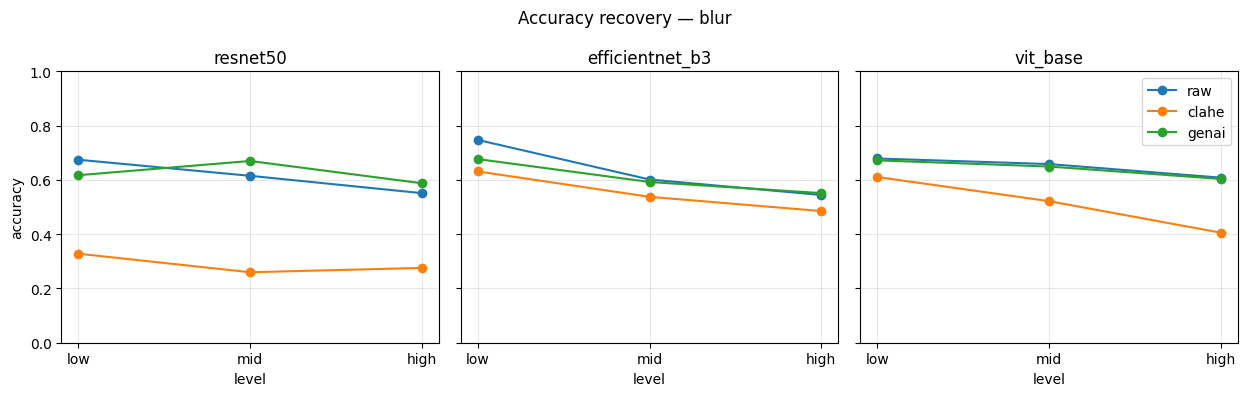

Saved: /content/drive/MyDrive/Thesis/results/phase4_genai_enhancement/plots/recovery_accuracy_blur.png


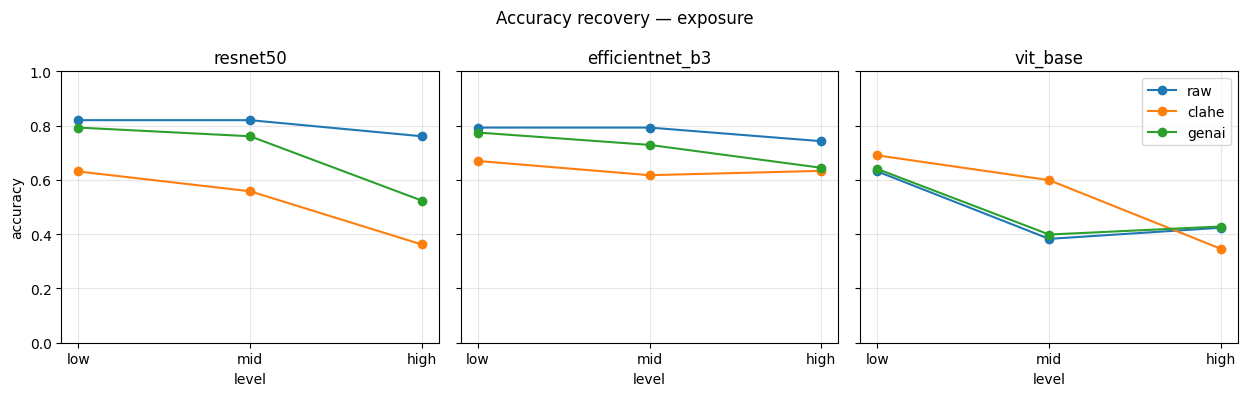

Saved: /content/drive/MyDrive/Thesis/results/phase4_genai_enhancement/plots/recovery_accuracy_exposure.png


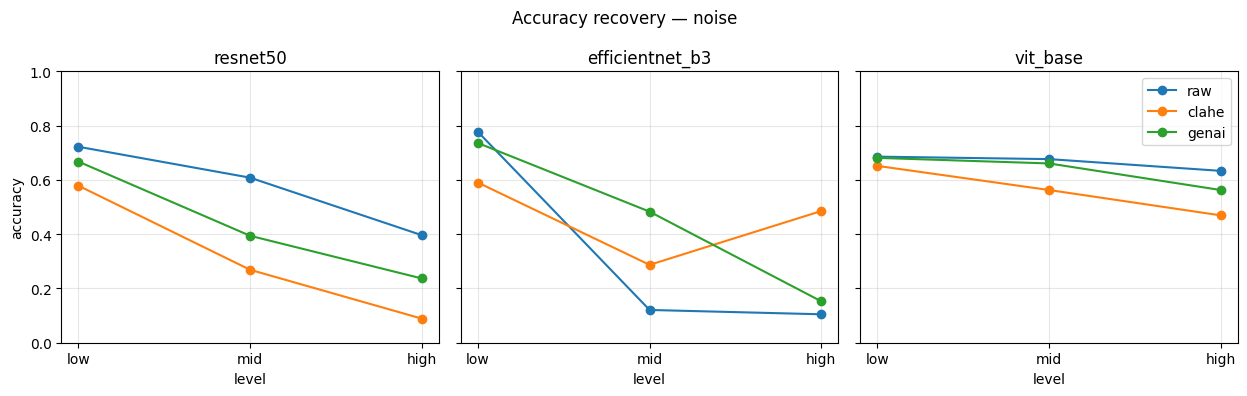

Saved: /content/drive/MyDrive/Thesis/results/phase4_genai_enhancement/plots/recovery_accuracy_noise.png


In [ ]:
# 4.5 Recovery plots — accuracy
level_order_no_none = ['low', 'mid', 'high']
for kind in DEGRADATION_TYPES:
    fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(4.2*len(MODEL_NAMES), 4), sharey=True)
    for ax, name in zip(axes, MODEL_NAMES):
        sub = rec_df[(rec_df['degradation'] == kind) & (rec_df['model'] == name)].copy()
        sub['level'] = pd.Categorical(sub['level'], categories=level_order_no_none, ordered=True)
        for variant in ('raw', 'clahe', 'genai'):
            d = sub[sub['variant'] == variant].sort_values('level')
            ax.plot(d['level'], d['accuracy'], marker='o', label=variant)
        ax.set_title(name); ax.set_xlabel('level'); ax.set_ylim(0, 1); ax.grid(alpha=0.3)
    axes[0].set_ylabel('accuracy'); axes[-1].legend()
    fig.suptitle(f'Accuracy recovery — {kind}')
    plt.tight_layout()
    out = P4 / 'plots' / f'recovery_accuracy_{kind}.png'
    plt.savefig(out, dpi=150); plt.show(); print('Saved:', out)

In [ ]:
# 4.6 Slim XAI re-evaluation on enhanced images
METHOD_FOR = {'resnet50': ('gradcam', gradcam_heatmap),
               'efficientnet_b3': ('gradcam', gradcam_heatmap),
               'vit_base': ('attention', attention_rollout)}
EXPLAIN_IDS_P4 = list(test_id_set)[:15]

rows = []
for name in MODEL_NAMES:
    method_name, fn = METHOD_FOR[name]
    model = load_classifier(name)
    print(f'\n=== {name} / {method_name} ===')
    for id_code in tqdm(EXPLAIN_IDS_P4):
        if id_code not in labels_df.index: continue
        label = int(labels_df[id_code])
        try:
            x_c = load_tensor(resolve_image(id_code))    # <-- was hardcoded .png
        except FileNotFoundError:
            continue
        try: h_c = fn(model, x_c, label)
        except Exception: continue
        for k in DEGRADATION_TYPES:
            for l in DEGRADATION_LEVELS:
                for variant in ('raw', *ENHANCERS):
                    base = DEGRADED_DIR if variant == 'raw' else ENHANCED_DIR / variant
                    try:
                        src = find_in_folder(base / k / l, id_code)   # <-- ext-agnostic
                    except FileNotFoundError:
                        continue
                    x = load_tensor(src)
                    try: h = fn(model, x, label)
                    except Exception: continue
                    rows.append({'id_code': id_code, 'model': name, 'method': method_name,
                                 'degradation': k, 'level': l, 'variant': variant,
                                 'stability': stability_spearman(h_c, h),
                                 'insertion_auc': insertion_auc(model, x, h, label)})
    del model; torch.cuda.empty_cache()

xai_rec = pd.DataFrame(rows)
xai_rec.to_csv(P4 / 'metrics' / 'recovery_xai.csv', index=False)
xai_rec.head()


=== resnet50 / gradcam ===


  0%|          | 0/15 [00:00<?, ?it/s]

/tmp/ipykernel_1352/1518898244.py:32: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, _ = spearmanr(h1.flatten(), h2.flatten())



=== efficientnet_b3 / gradcam ===


  0%|          | 0/15 [00:00<?, ?it/s]


=== vit_base / attention ===


  0%|          | 0/15 [00:00<?, ?it/s]

,id_code,model,method,degradation,level,variant,stability,insertion_auc
0,bb5083fae98f,resnet50,gradcam,blur,low,raw,0.673305,0.169575
1,bb5083fae98f,resnet50,gradcam,blur,low,clahe,0.658643,0.294977
2,bb5083fae98f,resnet50,gradcam,blur,low,genai,0.570514,0.168946
3,bb5083fae98f,resnet50,gradcam,blur,mid,raw,0.323868,0.066175
4,bb5083fae98f,resnet50,gradcam,blur,mid,clahe,0.538044,0.207895


/tmp/ipykernel_1352/2835154700.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'variant', 'level'])[metric].mean().reset_index()


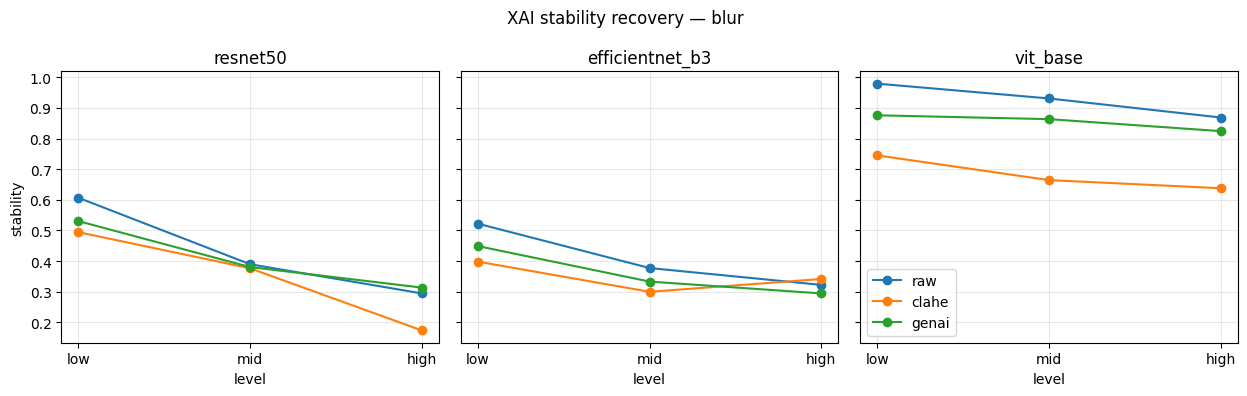

/tmp/ipykernel_1352/2835154700.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'variant', 'level'])[metric].mean().reset_index()


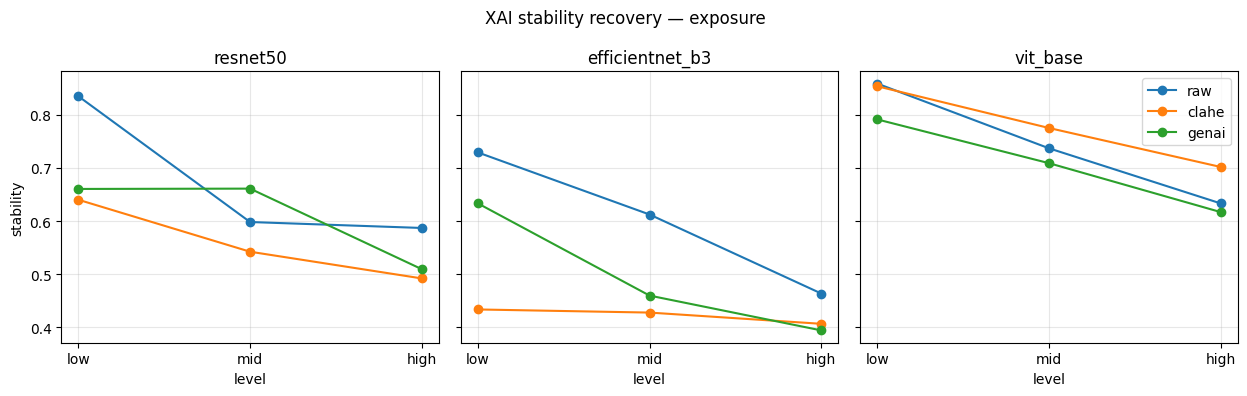

/tmp/ipykernel_1352/2835154700.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'variant', 'level'])[metric].mean().reset_index()


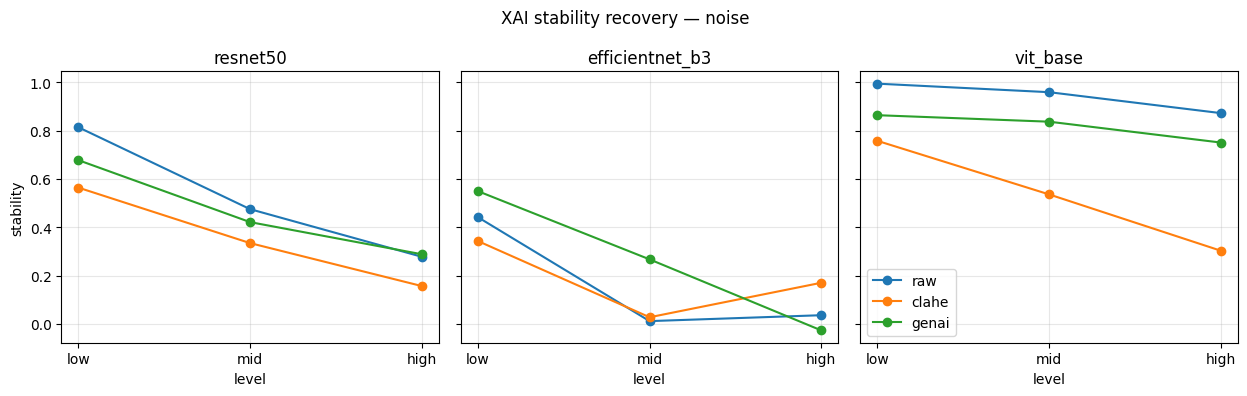

/tmp/ipykernel_1352/2835154700.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'variant', 'level'])[metric].mean().reset_index()


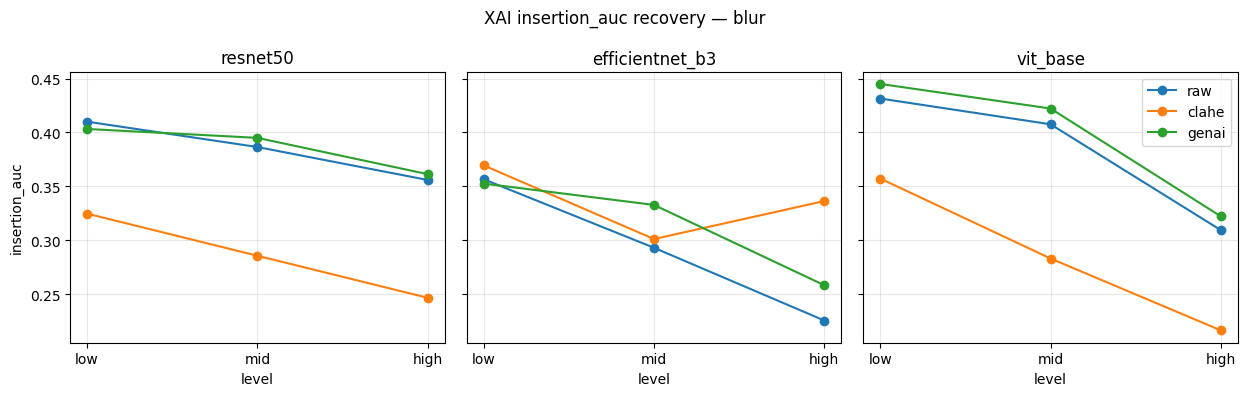

/tmp/ipykernel_1352/2835154700.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'variant', 'level'])[metric].mean().reset_index()


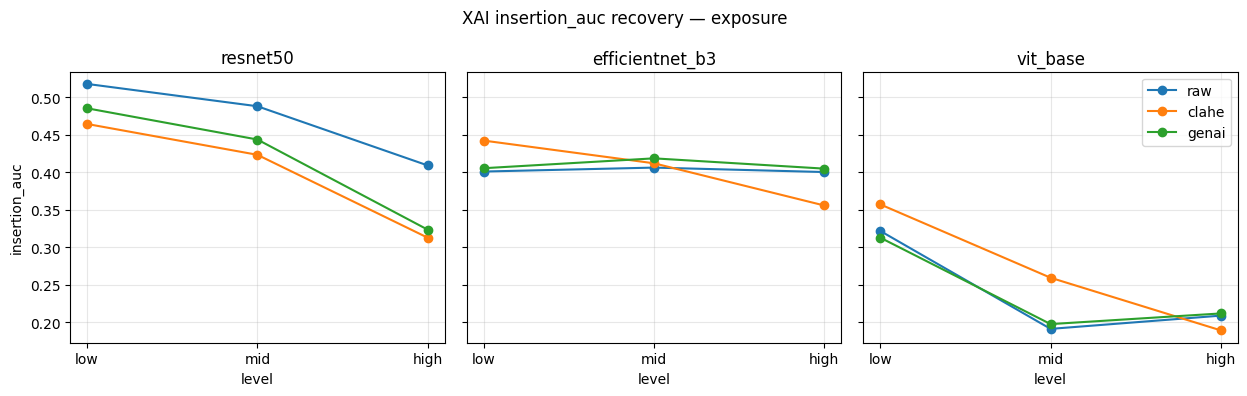

/tmp/ipykernel_1352/2835154700.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'variant', 'level'])[metric].mean().reset_index()


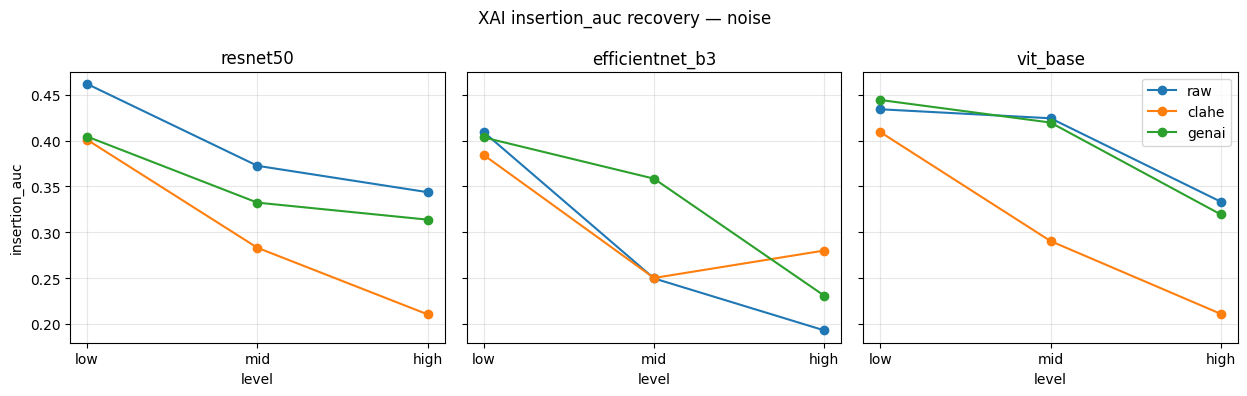

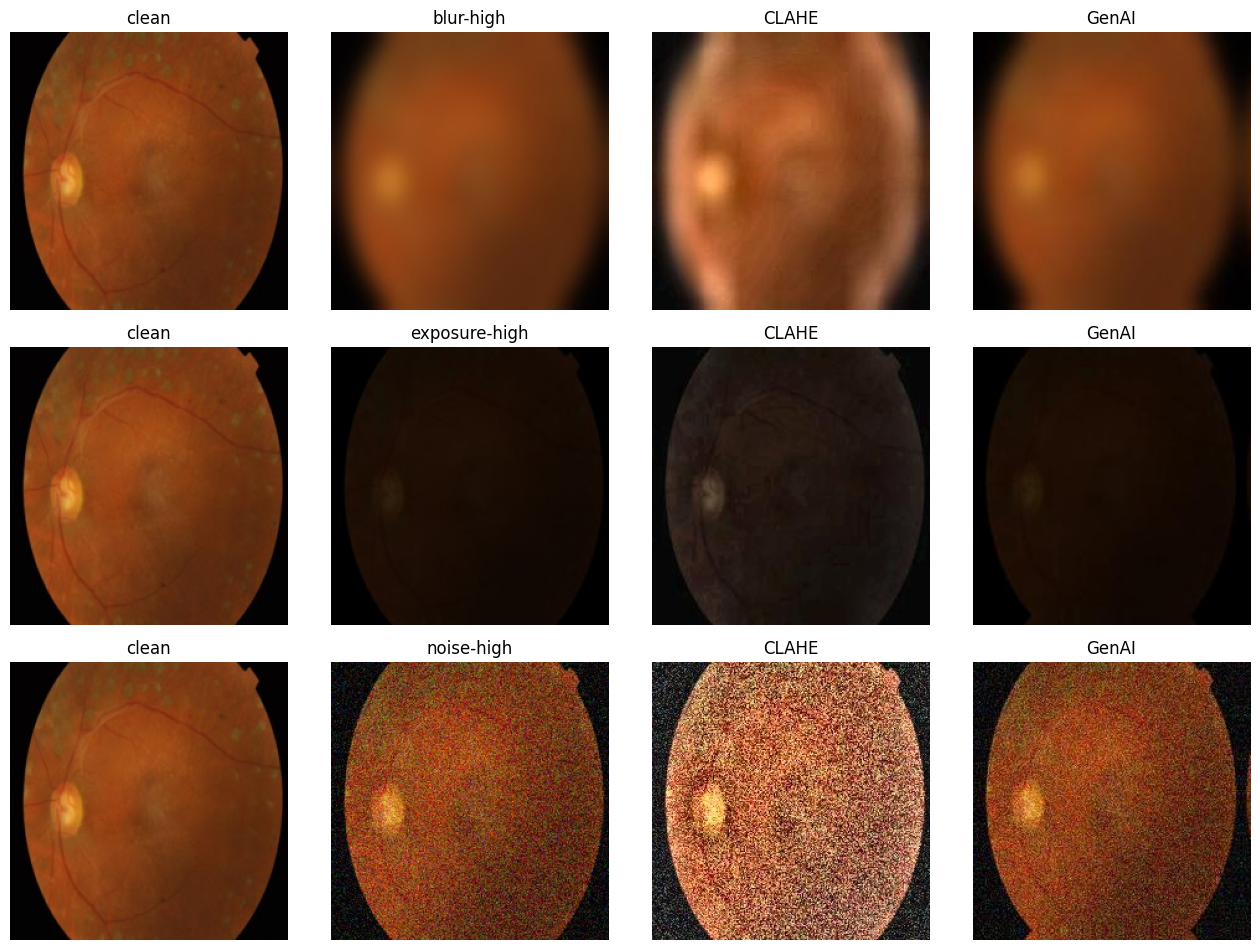

Saved: /content/drive/MyDrive/Thesis/results/phase4_genai_enhancement/samples/recovery_bb5083fae98f.png


In [ ]:
# 4.7 Recovery plots — XAI  (top half stays the same; only the qualitative block changes)
for metric in ('stability', 'insertion_auc'):
    for kind in DEGRADATION_TYPES:
        sub = xai_rec[xai_rec['degradation'] == kind].copy()
        if sub.empty: continue
        sub['level'] = pd.Categorical(sub['level'], categories=level_order_no_none, ordered=True)
        g = sub.groupby(['model', 'variant', 'level'])[metric].mean().reset_index()
        fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(4.2*len(MODEL_NAMES), 4), sharey=True)
        for ax, name in zip(axes, MODEL_NAMES):
            for variant in ('raw', 'clahe', 'genai'):
                d = g[(g['model'] == name) & (g['variant'] == variant)].sort_values('level')
                ax.plot(d['level'], d[metric], marker='o', label=variant)
            ax.set_title(name); ax.grid(alpha=0.3); ax.set_xlabel('level')
        axes[0].set_ylabel(metric); axes[-1].legend()
        fig.suptitle(f'XAI {metric} recovery — {kind}'); plt.tight_layout()
        out = P4 / 'plots' / f'recovery_xai_{metric}_{kind}.png'
        plt.savefig(out, dpi=150); plt.show()

# Side-by-side qualitative — extension-agnostic
demo_id = EXPLAIN_IDS_P4[0]
fig, axes = plt.subplots(len(DEGRADATION_TYPES), 4, figsize=(13, 3.2*len(DEGRADATION_TYPES)))
for r, kind in enumerate(DEGRADATION_TYPES):
    clean = Image.open(resolve_image(demo_id)).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
    deg   = Image.open(find_in_folder(DEGRADED_DIR / kind / 'high', demo_id)).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
    cl    = Image.open(find_in_folder(ENHANCED_DIR / 'clahe' / kind / 'high', demo_id)).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
    gn    = Image.open(find_in_folder(ENHANCED_DIR / 'genai' / kind / 'high', demo_id)).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
    for ax, im, ttl in zip(axes[r], (clean, deg, cl, gn), ('clean', f'{kind}-high', 'CLAHE', 'GenAI')):
        ax.imshow(im); ax.set_title(ttl); ax.axis('off')
plt.tight_layout()
out = P4 / 'samples' / f'recovery_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)

In [ ]:
P5 = PHASE_DIRS['phase5_quality_ensemble']

# 5.1 Train (or load) an EyeQ quality classifier (good/usable/reject)
class EyeQDataset(Dataset):
    def __init__(self, csv_path, images_root, transform,
                 id_col='image', quality_col='quality'):
        self.df = pd.read_csv(csv_path); self.df[id_col] = self.df[id_col].astype(str)
        self.images_root = Path(images_root); self.transform = transform
        self.id_col, self.quality_col = id_col, quality_col
        all_imgs = {p.stem: p for p in self.images_root.rglob('*.*')
                    if p.suffix.lower() in ('.png', '.jpg', '.jpeg')}
        self.df['__path'] = self.df[id_col].apply(lambda s: all_imgs.get(Path(s).stem))
        self.df = self.df.dropna(subset=['__path']).reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row['__path']).convert('RGB')
        return self.transform(img), int(row[self.quality_col])

In [ ]:
def build_quality_model(): return timm.create_model('resnet18', pretrained=True, num_classes=3)
Q_CKPT = CHECKPOINTS_DIR / 'quality_classifier.pt'

In [ ]:
def train_quality(epochs=2, bs=32):
    if EYEQ_CSV is None: return None
    ds = EyeQDataset(EYEQ_CSV, EYEQ_DIR, TFM_TRAIN)
    n_val = max(1, int(0.15 * len(ds)))
    tds, vds = random_split(ds, [len(ds)-n_val, n_val], generator=torch.Generator().manual_seed(0))
    vds.dataset = EyeQDataset(EYEQ_CSV, EYEQ_DIR, TFM_EVAL)
    tl = DataLoader(tds, batch_size=bs, shuffle=True,  num_workers=2)
    vl = DataLoader(vds, batch_size=bs, shuffle=False, num_workers=2)
    mdl = build_quality_model().to(DEVICE)
    optim = torch.optim.AdamW(mdl.parameters(), lr=3e-4, weight_decay=1e-4); crit = nn.CrossEntropyLoss()
    for ep in range(epochs):
        mdl.train()
        for x, y in tl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optim.zero_grad(); crit(mdl(x), y).backward(); optim.step()
        mdl.eval(); ys, ps = [], []
        with torch.no_grad():
            for x, y in vl:
                ps.append(mdl(x.to(DEVICE)).argmax(1).cpu().numpy()); ys.append(y.numpy())
        y = np.concatenate(ys); p = np.concatenate(ps)
        print(f'epoch {ep+1}: val acc = {accuracy_score(y, p):.4f}')
    rep = classification_report(y, p, target_names=list(EYEQ_QUALITY_LABELS.values()),
                                 output_dict=True, zero_division=0)
    torch.save(mdl.state_dict(), Q_CKPT)
    with open(P5 / 'metrics' / 'quality_classifier_metrics.json', 'w') as f:
        json.dump(rep, f, indent=2)
    return mdl

In [ ]:
if Q_CKPT.exists():
    qmodel = build_quality_model().to(DEVICE)
    qmodel.load_state_dict(torch.load(Q_CKPT, map_location=DEVICE)); qmodel.eval()
    print('Loaded existing quality classifier.')
else:
    qmodel = train_quality()

epoch 1: val acc = 0.8896
epoch 2: val acc = 0.8999


In [ ]:
# 5.2 Pick best_clean and best_robust from Phase 2 results
stress_df = pd.read_csv(P2 / 'metrics' / 'stress_test_results.csv')
best_clean  = stress_df[stress_df['degradation'] == 'clean'].sort_values('accuracy', ascending=False).iloc[0]['model']
best_robust = stress_df[stress_df['degradation'] != 'clean'].groupby('model')['accuracy'].mean().idxmax()
print('best_clean :', best_clean)
print('best_robust:', best_robust)

ROUTES = {
    'good':   {'enhancement': 'none',  'model': best_clean,  'xai': 'attention' if best_clean  == 'vit_base' else 'gradcam'},
    'usable': {'enhancement': 'clahe', 'model': best_clean,  'xai': 'attention' if best_clean  == 'vit_base' else 'gradcam'},
    'reject': {'enhancement': 'genai', 'model': best_robust, 'xai': 'attention' if best_robust == 'vit_base' else 'gradcam'},
}
ROUTES

best_clean : resnet50
best_robust: resnet50


{'good': {'enhancement': 'none', 'model': 'resnet50', 'xai': 'gradcam'},
 'usable': {'enhancement': 'clahe', 'model': 'resnet50', 'xai': 'gradcam'},
 'reject': {'enhancement': 'genai', 'model': 'resnet50', 'xai': 'gradcam'}}

In [ ]:
# 5.3 Pipeline function (quality -> route -> enhance -> classify -> XAI -> trust)
classifiers = {n: load_classifier(n) for n in {best_clean, best_robust}}
USE_PRECOMPUTED_GENAI = (ENHANCED_DIR / 'genai').exists()

def predict_quality(img):
    if qmodel is None: return 'good'
    x = TFM_EVAL(img).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        return EYEQ_QUALITY_LABELS[int(qmodel(x).argmax(1).item())]

def apply_enhancement(img, kind, kind_hint=None, level_hint=None, id_hint=None):
    if kind == 'none':  return img
    if kind == 'clahe': return enhance_clahe(img)
    if kind == 'genai':
        if USE_PRECOMPUTED_GENAI and kind_hint and level_hint and id_hint:
            cached = ENHANCED_DIR / 'genai' / kind_hint / level_hint / f'{id_hint}.png'
            if cached.exists(): return Image.open(cached).convert('RGB')
        return enhance_genai(img)
    return img

XAI_FNS = {'gradcam': gradcam_heatmap, 'attention': attention_rollout}

def trust_score(conf, insertion): return float(0.5 * conf + 0.5 * insertion)

def pipeline(img, kind_hint=None, level_hint=None, id_hint=None):
    quality  = predict_quality(img)
    route    = ROUTES[quality]
    enhanced = apply_enhancement(img, route['enhancement'],
                                  kind_hint=kind_hint, level_hint=level_hint, id_hint=id_hint)
    model = classifiers[route['model']]
    x = TFM_EVAL(enhanced).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        prob = torch.softmax(model(x), 1)[0]
        pred = int(prob.argmax().item()); conf = float(prob[pred].item())
    heat = XAI_FNS[route['xai']](model, x, target_class=pred)
    ins  = insertion_auc(model, x, heat, pred)
    return {'quality_pred': quality, 'route': route, 'pred': pred, 'conf': conf,
            'insertion_auc': ins, 'trust': trust_score(conf, ins),
            'heatmap': heat, 'enhanced_img': enhanced}

In [ ]:
# 5.4 Run pipeline on test set: clean + blur-high + exposure-high
EVAL_CONDITIONS = [('clean', None, None),
                    ('blur',     'blur',     'high'),
                    ('exposure', 'exposure', 'high')]

rows = []
for id_code in tqdm(list(test_id_set)[:80], desc='ensemble'):    # cap 80 for time
    if id_code not in labels_df.index: continue
    label = int(labels_df[id_code])
    for tag, kind, level in EVAL_CONDITIONS:
        src = resolve_image(id_code) if tag == 'clean' \
              else find_in_folder(DEGRADED_DIR / kind / level, id_code)
        if not src.exists(): continue
        out = pipeline(Image.open(src).convert('RGB'),
                       kind_hint=kind, level_hint=level, id_hint=id_code)
        rows.append({'id_code': id_code, 'condition': tag, 'true_label': label,
                     'pred': out['pred'], 'correct': int(out['pred'] == label),
                     'quality_pred': out['quality_pred'],
                     'route_model': out['route']['model'],
                     'route_enhancement': out['route']['enhancement'],
                     'route_xai': out['route']['xai'],
                     'conf': out['conf'], 'insertion_auc': out['insertion_auc'],
                     'trust': out['trust']})

ens_df = pd.DataFrame(rows)
ens_df.to_csv(P5 / 'metrics' / 'ensemble_predictions.csv', index=False)
ens_df.head()

ensemble:   0%|          | 0/80 [00:00<?, ?it/s]

,id_code,condition,true_label,pred,correct,quality_pred,route_model,route_enhancement,route_xai,conf,insertion_auc,trust
0,bb5083fae98f,clean,3,4,0,good,resnet50,none,gradcam,0.555225,0.514235,0.534730
1,bb5083fae98f,blur,3,0,0,reject,resnet50,genai,gradcam,0.682191,0.696822,0.689506
2,bb5083fae98f,exposure,3,2,0,reject,resnet50,genai,gradcam,0.296676,0.320852,0.308764
3,94076a9fb9b5,clean,0,0,1,good,resnet50,none,gradcam,0.913680,0.854948,0.884314
4,94076a9fb9b5,blur,0,0,1,reject,resnet50,genai,gradcam,0.651691,0.707879,0.679785


In [ ]:
# 5.5 Aggregate vs single-best baseline (Phase 2)
summary = (ens_df.groupby('condition')
                  .agg(accuracy=('correct', 'mean'),
                       mean_trust=('trust', 'mean'),
                       mean_insertion=('insertion_auc', 'mean'),
                       n=('id_code', 'count'))).round(4).reset_index()
baseline = (stress_df[stress_df['model'] == best_clean]
             .assign(condition=lambda d: np.where(d['degradation'] == 'clean', 'clean',
                                                  d['degradation'] + '-' + d['level']))
             [['condition', 'accuracy', 'f1_macro']]
             .rename(columns={'accuracy': 'baseline_acc', 'f1_macro': 'baseline_f1'}))
summary = summary.merge(baseline, on='condition', how='left')
summary.to_csv(P5 / 'metrics' / 'ensemble_summary.csv', index=False)
summary

,condition,accuracy,mean_trust,mean_insertion,n,baseline_acc,baseline_f1
0,blur,0.6000,0.6805,0.7037,80,NaN,NaN
1,clean,0.7375,0.7456,0.7076,80,0.838269,0.67033
2,exposure,0.7375,0.6735,0.6502,80,NaN,NaN


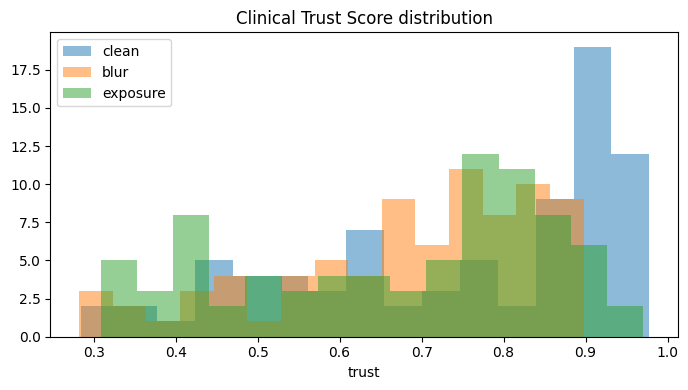

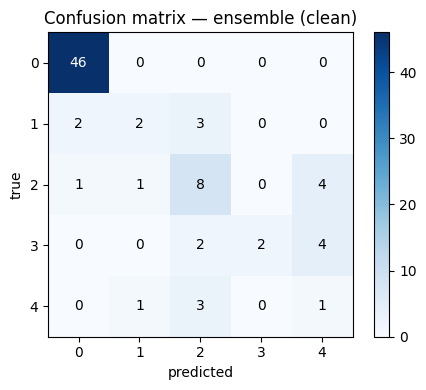

In [ ]:
# 5.6 Plots
fig, ax = plt.subplots(figsize=(7, 4))
for cond in ens_df['condition'].unique():
    ax.hist(ens_df.loc[ens_df['condition'] == cond, 'trust'], bins=15, alpha=0.5, label=cond)
ax.set_title('Clinical Trust Score distribution'); ax.set_xlabel('trust'); ax.legend()
plt.tight_layout()
plt.savefig(P5 / 'plots' / 'trust_score_distribution.png', dpi=150); plt.show()

clean = ens_df[ens_df['condition'] == 'clean']
if not clean.empty:
    cm = confusion_matrix(clean['true_label'], clean['pred'], labels=list(range(NUM_CLASSES)))
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm, cmap='Blues')
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > cm.max()/2 else 'black')
    ax.set_xlabel('predicted'); ax.set_ylabel('true')
    ax.set_title('Confusion matrix — ensemble (clean)'); fig.colorbar(im)
    plt.tight_layout()
    plt.savefig(P5 / 'plots' / 'confusion_matrix.png', dpi=150); plt.show()

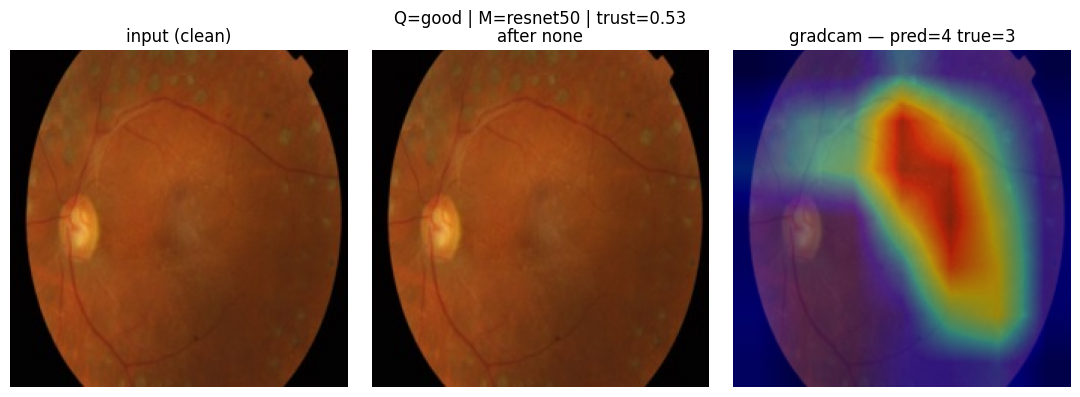

Saved: /content/drive/MyDrive/Thesis/results/phase5_quality_ensemble/samples/route_bb5083fae98f_clean.png


In [ ]:
# 5.7 Qualitative — one routed example
demo = ens_df.iloc[0]
src = resolve_image(demo['id_code']) if demo['condition'] == 'clean' \
      else find_in_folder(DEGRADED_DIR / demo['condition'] / 'high', demo['id_code'])
img = Image.open(src).convert('RGB')
out = pipeline(img,
               kind_hint=None if demo['condition'] == 'clean' else demo['condition'],
               level_hint=None if demo['condition'] == 'clean' else 'high',
               id_hint=demo['id_code'])
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(img.resize((IMAGE_SIZE, IMAGE_SIZE))); axes[0].set_title(f'input ({demo["condition"]})')
axes[1].imshow(out['enhanced_img'].resize((IMAGE_SIZE, IMAGE_SIZE)))
axes[1].set_title(f"after {out['route']['enhancement']}")
axes[2].imshow(out['enhanced_img'].resize((IMAGE_SIZE, IMAGE_SIZE)))
axes[2].imshow(out['heatmap'], cmap='jet', alpha=0.45)
axes[2].set_title(f"{out['route']['xai']} — pred={out['pred']} true={demo['true_label']}")
for ax in axes: ax.axis('off')
fig.suptitle(f"Q={out['quality_pred']} | M={out['route']['model']} | trust={out['trust']:.2f}")
plt.tight_layout()
save = P5 / 'samples' / f"route_{demo['id_code']}_{demo['condition']}.png"
plt.savefig(save, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', save)